# Elliptical Trajectory Conditions (Smaller Scale) and CNN Inference

We reduced ellipse perimeter from 160 cm to **32 cm**, retained the **2.5 s period**, and kept the same relative velocity modulation and slowing locations. Average speed is therefore 12.8 cm/s. This is a scaled exploratory test of the idea, not an exact replication of the human experiment.

Sources: Viviani, Baud-Bovy & Redolfi (1997), Experiment 1, Table 1 and Figure 3, [primary paper](../../Elliptical%20Trajectories/Perceiving_and_Tracking_Kinesthetic_Stimuli_Furthe%20(1).pdf). Published pretrained weights: [Zenodo 15111808](https://zenodo.org/records/15111808). The older full-size ensemble notebook is archived under `notebooks/archive/` and is not run here.


**Aligned protocol update:** shoulder-height placement, participant-left starting point, and counterclockwise movement. The single `0_9` checkpoint is used again. Human uncertainty and model reconstruction-error bars are defined explicitly in Sections 4–5.


**Research-meeting audit (19 November 2026):** Section 7 below distinguishes the published protocol from this scaled simulation, quantifies arm posture and spindle ranges, and reports a separate comparison across all 20 matched archived checkpoint variants. Sections 1–6 retain their original single-CNN interpretation. Matching the movement plane did **not** reproduce the paper's almost extended, maintained palm-down arm posture.


## 1. Elliptical trajectories being tested

Positive signed eccentricity means a horizontal ellipse; negative means vertical. Seven shapes × three velocity conditions give **21 trajectories**. A has constant tangential speed. B slows at the left/right extremes. C slows at the top/bottom. Spatial scaling changes absolute speeds but preserves the phase and the relative speed pattern exactly; this invariant is checked in the tests.

Paths are now centered at right-shoulder height in a frontoparallel plane 45 cm anterior to the model's torso reference origin. That torso origin approximates the study's chest reference because the model has no chest-surface marker. Each trajectory starts at the participant's leftmost point and initially moves downward: counterclockwise from their view. The circle radius is 5.09 cm; the most elongated ellipse has semiaxes about 7.54 and 2.35 cm. Three cycles are generated; shape readout uses the final cycle.

The reference Lissajous eccentricity remains .9, giving a speed ratio 2.294. The paper's stated numerical ratio 3.205 corresponds to .95; changing that parameter is a separate sensitivity test.

**Axes:** model ground Z points toward the right arm, while the pipeline uses X = −ground Z. All horizontal plots below therefore use participant-right = −pipeline X, and vertical = pipeline Z. The earlier plots were mirrored horizontally. Starting at full prescribed speed is retained; the paper's half-cycle acceleration ramp and self-paced stopping are not reproduced.


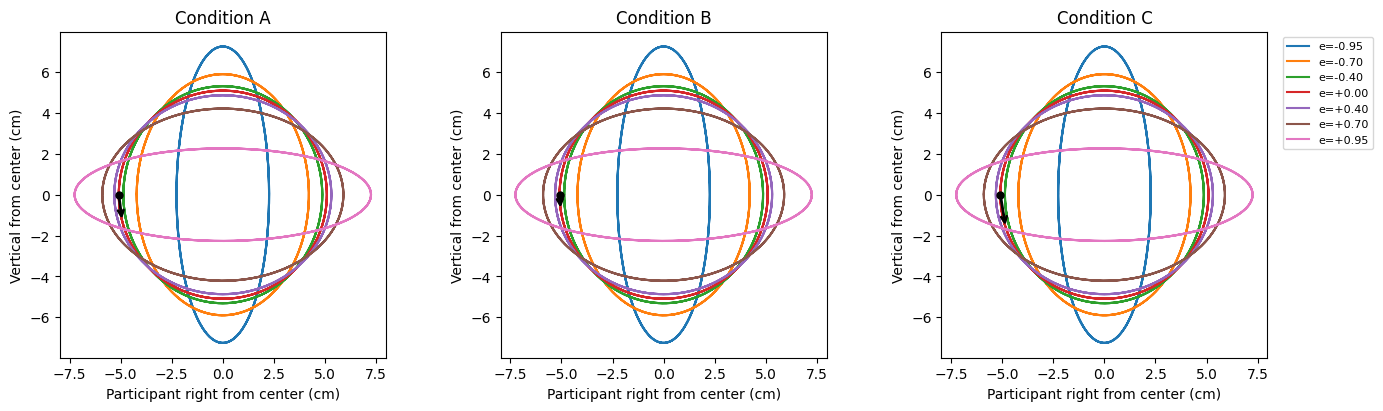

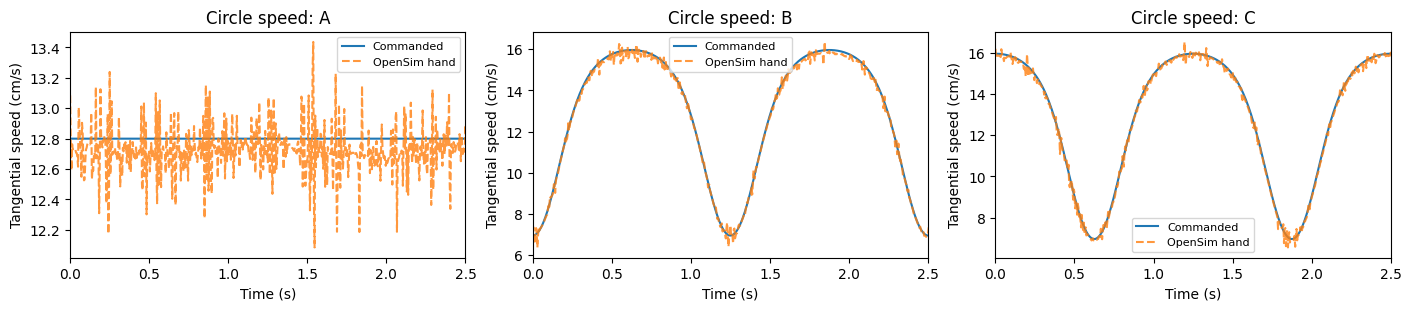

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_pipeline.py').exists())
CONFIG_PATH=ROOT/'experiments/viviani_aligned.yaml'
CONFIG=yaml.safe_load(CONFIG_PATH.read_text())
OUT=ROOT/'outputs'/CONFIG['experiment'];OUT.mkdir(exist_ok=True)
OPEN_SIM_PYTHON=ROOT/'.venv-opensim/bin/python'
INFERENCE_PYTHON=ROOT/'.venv-mujoco/bin/python'
CHECKPOINT=ROOT/CONFIG['proprioception']['model_path']
RUN_BIOMECHANICS=False  # True reruns the original path → IK → motion → muscle → spindle stages.
RUN_INFERENCE=False  # True reruns the original inference stage, with just the configured CNN.
CIRCLE_RATIO_TOLERANCE=1.05
CLASSES=['true circle','horizontal ellipse','vertical ellipse']
PERIOD=CONFIG['path']['ellipse']['period_s'];FS=CONFIG['path']['sample_rate_hz']
plt.rcParams.update({'font.size':10,'figure.figsize':(10,4)})
def participant_xz(xyz):
    return np.asarray(xyz)[:,[0,2]]*np.array([-1.,1.])

CONFIG_SIGNATURE=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()

def run_stage(stage,python):
    (OUT/'.matplotlib').mkdir(exist_ok=True)
    command=[str(python),'-c',f"from run_pipeline import Pipeline; Pipeline({str(CONFIG_PATH)!r}).run_stage({stage!r})"]
    env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(OUT/'.matplotlib'))
    log=OUT/(stage+'.log')
    with log.open('w') as stream:
        result=subprocess.run(command,cwd=ROOT,env=env,stdout=stream,stderr=subprocess.STDOUT)
    if result.returncode:raise RuntimeError(f'{stage} failed: {log}\n'+log.read_text()[-2000:])
    print('Completed',stage)

if RUN_BIOMECHANICS:
    for stage in ['path','inverse-kinematics','motion','muscle-lengths','muscle-signals']:run_stage(stage,OPEN_SIM_PYTHON)
stimuli=pd.read_csv(OUT/'stimuli.csv')
manifest=yaml.safe_load((OUT/'manifest.yaml').read_text());entries={r['id']:r for r in manifest['trajectories']}
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    for row in stimuli[stimuli.condition==condition].itertuples():
        d=np.load(OUT/entries[row.id]['desired_path']);center=d['center_xyz'];xy=participant_xz(d['xyz']-center)
        ax.plot(*xy.T,label=f'e={row.e:+.2f}')
        if row.e==0:
            ax.scatter(*xy[0],c='black',s=25,zorder=5)
            ax.annotate('',xy=xy[25],xytext=xy[0],arrowprops=dict(arrowstyle='->',color='black',lw=2))
    ax.set(title=f'Condition {condition}',xlabel='Participant right from center (cm)',ylabel='Vertical from center (cm)',aspect='equal')
axes[-1].legend(fontsize=8,bbox_to_anchor=(1.03,1));plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,3),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    ident=stimuli[(stimuli.condition==condition)&(stimuli.e==0)].id.iloc[0]
    d=np.load(OUT/entries[ident]['desired_path']);speed=np.linalg.norm(np.gradient(d['xyz'],1/FS,axis=0),axis=1)
    ax.plot(d['times'],speed,label='Commanded')
    physical=np.load(OUT/entries[ident]['muscle_data'])
    delivered_speed=np.linalg.norm(np.gradient(physical['wrist_xyz_reference_world'],1/FS,axis=0),axis=1)
    ax.plot(physical['times'],delivered_speed,'--',label='OpenSim hand',alpha=.8)
    ax.set(xlim=(0,PERIOD),title=f'Circle speed: {condition}',xlabel='Time (s)',ylabel='Tangential speed (cm/s)');ax.legend(fontsize=8)
plt.show()


## 2. Check muscle paths, then calculate spindle firing rates

**Original-pipeline test:** a 32 cm circle at the original rest posture produced fibres around 19–208 mm, without the earlier metre-scale failures. This baseline is retained in `outputs/viviani_small_probe/`.

**First failed large-path sample:** `A_m0_40`, frame 0, teres minor (`TMIN`). Shoulder elevation was about 139.2°. Its saved fibre length was 2,217 mm; a fresh OpenSim model reproduced that value. The full muscle–tendon path was 2,631 mm. Inspection of `GeometryPath.getCurrentPath()` showed generated wrapping points far outside the shoulder region. This confirms a failed muscle route at that posture; it does not justify changing a wrapping surface globally.

**Correction:** use smaller paths in the aligned shoulder-height plane and align forearm rotation between IK and muscle extraction. The original IK brace was −30° while the training-compatible extractor used the model's 0° default. Both now use 0°, preserving the original four-coordinate muscle-input convention. The original OpenSim IK backend is retained; the original .001 posture regularization is retained to keep muscle signals smooth. No wrapping surfaces were disabled and no fibre lengths were clipped or replaced.

The graphs below inspect the failed and successful muscle routes and verify all 21 new conditions. These checks screen for simulation failures; they are not a full physiological validation. The spindle calculation is the existing 25-muscle, 5 Ia + 5 II pipeline with coefficient seed 0.

The hand-tracking screen is 0.2 cm (2 mm); delivered shape labels are also checked against commanded labels. A trial with reduced posture regularization improved marker error but caused joint/velocity jumps, so that setting was rejected before final inference.

The 3D diagnostic connects the path points returned by OpenSim; it does not render the curved wrapping arcs. Reported muscle–tendon lengths come directly from OpenSim.

**Posture reference at the new height:** a pilot circle supplied a nearer IK reference for elevation, elevation angle and elbow flexion; shoulder rotation retains the original 25° reference. This changes the simulation posture, not the CNN weights. Every final condition is screened again for path error, fibre length and fibre velocity before inference.


,id,max_hand_error_cm,min_fiber_mm,max_fiber_mm,min_normalized_length,max_normalized_length,peak_velocity_mm_s,min_rate_hz,max_rate_hz,delivered_class,delivered_ratio,passed
0,A_m0_95,0.074868,17.319443,233.847458,0.638855,1.422756,247.613510,0.0,32.145386,vertical ellipse,0.311157,True
1,B_m0_95,0.074836,17.320299,233.854675,0.638861,1.422752,245.641464,0.0,32.102406,vertical ellipse,0.311213,True
2,C_m0_95,0.075606,17.319784,233.849670,0.638010,1.422763,244.971298,0.0,31.563774,vertical ellipse,0.311128,True
3,A_m0_70,0.072091,17.461544,232.716354,0.634540,1.423171,253.278793,0.0,31.416918,vertical ellipse,0.711045,True
4,B_m0_70,0.074896,17.462477,232.604630,0.634506,1.423175,238.914169,0.0,30.956509,vertical ellipse,0.711081,True
5,C_m0_70,0.074869,17.461010,232.729156,0.634533,1.423188,237.156357,0.0,30.453293,vertical ellipse,0.711060,True
6,A_m0_40,0.077095,17.516512,232.193115,0.632479,1.423296,234.871201,0.0,30.347000,vertical ellipse,0.912516,True
7,B_m0_40,0.077671,17.516804,232.180237,0.633023,1.423386,235.360092,0.0,30.480856,vertical ellipse,0.912653,True
8,C_m0_40,0.075748,17.516285,232.204269,0.633003,1.423299,233.979477,0.0,30.064438,vertical ellipse,0.912371,True
9,A_p0_00,0.078776,17.536245,232.007004,0.632851,1.423340,233.505234,0.0,30.180302,true circle,0.995850,True


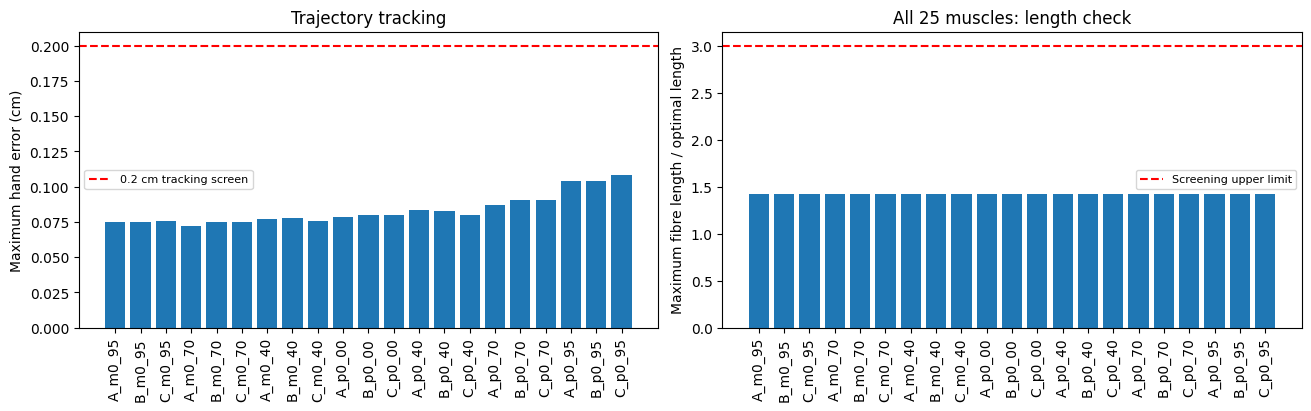

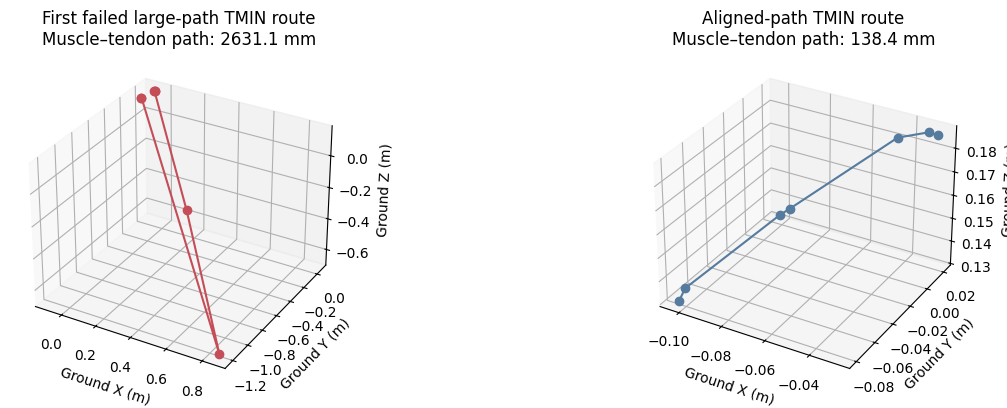

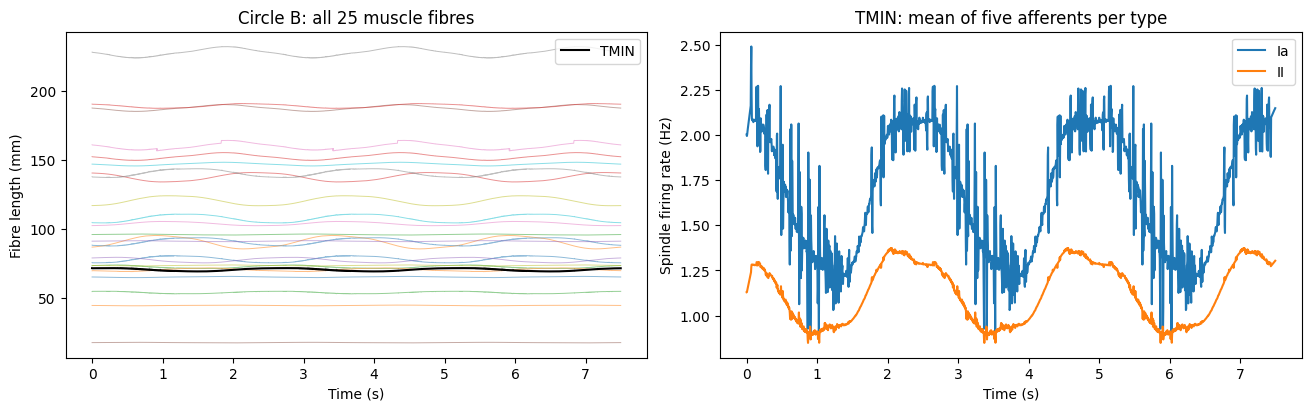

All 21 stimuli pass the simulation checks.


In [2]:
optimal=np.asarray(yaml.safe_load((ROOT/'extract_data/configs/train_test_data_spindles_extended.yaml').read_text())['optimal_lengths'])
quality=[]
for row in stimuli.itertuples():
    item=entries[row.id];desired=np.load(OUT/item['desired_path']);muscle=np.load(OUT/item['muscle_data']);spindle=np.load(OUT/item['spindle_data'])
    lengths=muscle['fiber_lengths'];ratio=lengths/optimal[None,:]
    error=np.linalg.norm(muscle['wrist_xyz_reference_world']-desired['xyz'],axis=1)
    extent=np.ptp(muscle['wrist_xyz_reference_world'][-600:,[0,2]],axis=0)
    delivered_ratio=extent[0]/extent[1]
    delivered_class=CLASSES[0] if 1/CIRCLE_RATIO_TOLERANCE<=delivered_ratio<=CIRCLE_RATIO_TOLERANCE else CLASSES[1 if delivered_ratio>1 else 2]
    peak_velocity=np.abs(np.gradient(lengths,1/FS,axis=0)).max()
    rates=spindle['firing_rates']
    passed=bool(np.isfinite(lengths).all() and np.isfinite(rates).all() and ratio.min()>.1 and ratio.max()<3 and error.max()<.2 and peak_velocity<500 and delivered_class==row.correct)
    quality.append(dict(id=row.id,max_hand_error_cm=error.max(),min_fiber_mm=lengths.min(),max_fiber_mm=lengths.max(),min_normalized_length=ratio.min(),max_normalized_length=ratio.max(),peak_velocity_mm_s=peak_velocity,min_rate_hz=rates.min(),max_rate_hz=rates.max(),delivered_class=delivered_class,delivered_ratio=delivered_ratio,passed=passed))
quality=pd.DataFrame(quality);quality.to_csv(OUT/'quality.csv',index=False)
display(quality)
assert quality.passed.all(), 'A simulation check failed; inspect the inputs before running the CNN.'
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].bar(quality.id,quality.max_hand_error_cm);axes[0].axhline(.2,c='red',ls='--',label='0.2 cm tracking screen');axes[0].tick_params(axis='x',rotation=90);axes[0].set(ylabel='Maximum hand error (cm)',title='Trajectory tracking');axes[0].legend(fontsize=8)
axes[1].bar(quality.id,quality.max_normalized_length);axes[1].axhline(3,c='red',ls='--',label='Screening upper limit');axes[1].tick_params(axis='x',rotation=90);axes[1].set(ylabel='Maximum fibre length / optimal length',title='All 25 muscles: length check');axes[1].legend(fontsize=8);plt.show()
audit=json.loads((OUT/'muscle_path_audit.json').read_text())
fig=plt.figure(figsize=(13,4.5));fig.subplots_adjust(left=.03,right=.88,bottom=.10,top=.85,wspace=.30)
for index,key,title in [(1,'failed','First failed large-path TMIN route'),(2,'small','Aligned-path TMIN route')]:
    ax=fig.add_subplot(1,2,index,projection='3d');a=audit[key];xyz=np.array(a['path_points_ground_m'])
    ax.plot(*xyz.T,'o-',color='#c44d58' if key=='failed' else '#557b9e')
    ax.set(title=f"{title}\nMuscle–tendon path: {a['musculotendon_length_mm']:.1f} mm",xlabel='Ground X (m)',ylabel='Ground Y (m)',zlabel='Ground Z (m)')
plt.show()
ident=stimuli[(stimuli.condition=='B')&(stimuli.e==0)].id.iloc[0]
m=np.load(OUT/entries[ident]['muscle_data']);s=np.load(OUT/entries[ident]['spindle_data'])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].plot(m['times'],m['fiber_lengths'],alpha=.5,lw=.7)
i=list(m['muscle_names']).index('TMIN');axes[0].plot(m['times'],m['fiber_lengths'][:,i],c='black',lw=1.5,label='TMIN')
axes[0].set(xlabel='Time (s)',ylabel='Fibre length (mm)',title='Circle B: all 25 muscle fibres');axes[0].legend()
for start,label in [(0,'Ia'),(5,'II')]:
    axes[1].plot(s['times'],s['firing_rates'][0,start:start+5,i,:].mean(axis=0),label=label)
axes[1].set(xlabel='Time (s)',ylabel='Spindle firing rate (Hz)',title='TMIN: mean of five afferents per type');axes[1].legend();plt.show()
print('All',len(quality),'stimuli pass the simulation checks.')


## 3. Single-CNN reconstruction and shape classification

This runs `process/centeroutinference.py`, the inference stage already used in your codebase, with the configured `0_9` checkpoint. Its existing normalization and `replicate` temporal padding are preserved. The original 240 Hz timebase is retained. No other checkpoint is loaded.

The CNN outputs wrist XYZ and four joint angles. To read shape in the physical frontoparallel plane, its four predicted joint angles are placed in the same OpenSim model. Shape is measured from horizontal/vertical extent in the final cycle: a ratio within [1/1.05, 1.05] is labelled circle, greater is horizontal, smaller is vertical. This is a fixed geometric readout of the pretrained reconstruction, not a newly trained classification head or calibrated probability.


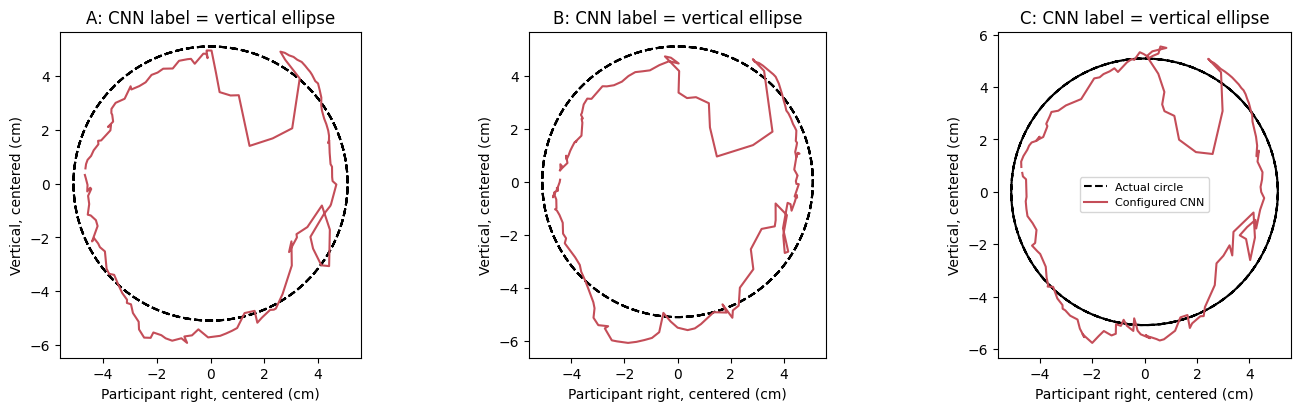

,id,correct,predicted,ratio,predicted_e,joint_out_of_bounds_fraction
0,A_m0_95,vertical ellipse,vertical ellipse,0.309867,-0.950780,0.0
1,B_m0_95,vertical ellipse,vertical ellipse,0.306586,-0.951843,0.0
2,C_m0_95,vertical ellipse,vertical ellipse,0.310188,-0.950675,0.0
3,A_m0_70,vertical ellipse,vertical ellipse,0.652628,-0.757678,0.0
4,B_m0_70,vertical ellipse,vertical ellipse,0.640562,-0.767906,0.0
5,C_m0_70,vertical ellipse,vertical ellipse,0.614375,-0.789014,0.0
6,A_m0_40,vertical ellipse,vertical ellipse,0.770818,-0.637055,0.0
7,B_m0_40,vertical ellipse,vertical ellipse,0.836986,-0.547224,0.0
8,C_m0_40,vertical ellipse,vertical ellipse,0.776949,-0.629563,0.0
9,A_p0_00,true circle,vertical ellipse,0.859863,-0.510525,0.0


Checkpoint: trained_models/experiment_causal_flag-pcr_optimized_linear_extended_5_5_letter_reconstruction_joints/spatiotemporal_4_8-8-32-64_7171_0_9
Models used: 1 | predictions: 21
Fraction of decoded frames outside joint limits: 0.0


PSE refinement: 15 additional trajectories; the same single checkpoint throughout.


In [3]:
if RUN_INFERENCE:
    run_stage('inference',INFERENCE_PYTHON)
    inventory=[]
    for row in stimuli.itertuples():
        item=yaml.safe_load((OUT/'manifest.yaml').read_text())
        entry=next(r for r in item['trajectories'] if r['id']==row.id)
        inventory.append(dict(id=row.id,condition=row.condition,e=row.e,coefficient_seed=CONFIG['proprioception']['coefficient_seed'],training_seed=CONFIG['proprioception']['training_seed'],predictions=entry['raw_predictions']))
    (OUT/'batch').mkdir(exist_ok=True)
    pd.DataFrame(inventory).to_csv(OUT/'batch/inventory.csv',index=False)
    (OUT/'generation.json').write_text(json.dumps(dict(signature=CONFIG_SIGNATURE)))
    with (OUT/'readout.log').open('w') as log:
        subprocess.run([str(OPEN_SIM_PYTHON),'process/ellipse_readout.py','--output',str(OUT),'--tolerance',str(CIRCLE_RATIO_TOLERANCE)],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
    provenance=dict(n_models=1,model_path=str(CHECKPOINT.relative_to(ROOT)),checkpoint_sha256=hashlib.sha256((CHECKPOINT/'model.ckpt').read_bytes()).hexdigest(),config_signature=CONFIG_SIGNATURE,temporal_padding=CONFIG['proprioception']['temporal_padding_mode'])
    (OUT/'single_model_provenance.json').write_text(json.dumps(provenance,indent=2))
provenance=json.loads((OUT/'single_model_provenance.json').read_text())
assert provenance['n_models']==1 and provenance['config_signature']==CONFIG_SIGNATURE
assert provenance['checkpoint_sha256']==hashlib.sha256((CHECKPOINT/'model.ckpt').read_bytes()).hexdigest()
assert json.loads((OUT/'batch/readout.json').read_text())['tolerance']==CIRCLE_RATIO_TOLERANCE
predictions=pd.read_csv(OUT/'batch/shape_predictions.csv')
assert len(predictions)==len(stimuli) and len(predictions[['coefficient_seed','training_seed']].drop_duplicates())==1
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    row=predictions[(predictions.condition==condition)&(predictions.e==0)].iloc[0]
    xyz=np.load(OUT/row.physical_prediction)['xyz'];xy=participant_xz(xyz);xy-=xy.mean(axis=0)
    desired=np.load(OUT/entries[row.id]['desired_path']);truth=participant_xz(desired['xyz']-desired['center_xyz'])
    ax.plot(*truth.T,'k--',label='Actual circle');ax.plot(*xy.T,c='#c44d58',label='Configured CNN')
    ax.set(title=f'{condition}: CNN label = {row.predicted}',xlabel='Participant right, centered (cm)',ylabel='Vertical, centered (cm)',aspect='equal')
axes[-1].legend(fontsize=8);plt.show()
display(predictions[['id','correct','predicted','ratio','predicted_e','joint_out_of_bounds_fraction']])
print('Checkpoint:',provenance['model_path'])
print('Models used:',provenance['n_models'],'| predictions:',len(predictions))
print('Fraction of decoded frames outside joint limits:',predictions.joint_out_of_bounds_fraction.mean())

# Focused numerical PSE refinement; this is the same checkpoint on new ellipses.
REFINE_CONFIG_PATH=ROOT/'experiments/viviani_aligned_refine.yaml'
REFINE_CONFIG=yaml.safe_load(REFINE_CONFIG_PATH.read_text())
REFINE_OUT=ROOT/'outputs'/REFINE_CONFIG['experiment']
REFINE_SIGNATURE=hashlib.sha256(json.dumps(REFINE_CONFIG,sort_keys=True).encode()).hexdigest()
assert REFINE_CONFIG['proprioception']==CONFIG['proprioception']
assert REFINE_CONFIG['ik']==CONFIG['ik'] and REFINE_CONFIG['path']['rest_pose_degrees']==CONFIG['path']['rest_pose_degrees']
def run_refine_stage(stage,python):
    command=[str(python),'-c',f"from run_pipeline import Pipeline; Pipeline({str(REFINE_CONFIG_PATH)!r}).run_stage({stage!r})"]
    env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(OUT/'.matplotlib'))
    with (REFINE_OUT/(stage+'.log')).open('w') as log:
        subprocess.run(command,cwd=ROOT,env=env,stdout=log,stderr=subprocess.STDOUT,check=True)
if RUN_BIOMECHANICS:
    for stage in ['path','inverse-kinematics','motion','muscle-lengths','muscle-signals']:run_refine_stage(stage,OPEN_SIM_PYTHON)
refine_stimuli=pd.read_csv(REFINE_OUT/'stimuli.csv')
refine_manifest=yaml.safe_load((REFINE_OUT/'manifest.yaml').read_text())
refine_quality=[]
for item in refine_manifest['trajectories']:
    muscle=np.load(REFINE_OUT/item['muscle_data']);desired=np.load(REFINE_OUT/item['desired_path']);lengths=muscle['fiber_lengths']
    error=np.linalg.norm(muscle['wrist_xyz_reference_world']-desired['xyz'],axis=1).max()
    velocity=np.abs(np.gradient(lengths,1/FS,axis=0)).max()
    passed=bool(np.isfinite(lengths).all() and (lengths/optimal).min()>.1 and (lengths/optimal).max()<3 and error<.2 and velocity<500)
    refine_quality.append(dict(id=item['id'],max_hand_error_cm=error,peak_velocity_mm_s=velocity,passed=passed))
refine_quality=pd.DataFrame(refine_quality);refine_quality.to_csv(REFINE_OUT/'quality.csv',index=False)
assert refine_quality.passed.all(), 'A PSE refinement input failed validation.'
if RUN_INFERENCE:
    run_refine_stage('inference',INFERENCE_PYTHON)
    refine_manifest=yaml.safe_load((REFINE_OUT/'manifest.yaml').read_text())
    inventory=[]
    for row in refine_stimuli.itertuples():
        entry=next(v for v in refine_manifest['trajectories'] if v['id']==row.id)
        inventory.append(dict(id=row.id,condition=row.condition,e=row.e,coefficient_seed=CONFIG['proprioception']['coefficient_seed'],training_seed=CONFIG['proprioception']['training_seed'],predictions=entry['raw_predictions']))
    (REFINE_OUT/'batch').mkdir(exist_ok=True)
    pd.DataFrame(inventory).to_csv(REFINE_OUT/'batch/inventory.csv',index=False)
    (REFINE_OUT/'generation.json').write_text(json.dumps(dict(signature=REFINE_SIGNATURE)))
    with (REFINE_OUT/'readout.log').open('w') as log:
        subprocess.run([str(OPEN_SIM_PYTHON),'process/ellipse_readout.py','--output',str(REFINE_OUT),'--tolerance',str(CIRCLE_RATIO_TOLERANCE)],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
    (REFINE_OUT/'single_model_provenance.json').write_text(json.dumps(dict(n_models=1,checkpoint_sha256=provenance['checkpoint_sha256'],config_signature=REFINE_SIGNATURE),indent=2))
refine_provenance=json.loads((REFINE_OUT/'single_model_provenance.json').read_text())
assert refine_provenance['config_signature']==REFINE_SIGNATURE and refine_provenance['checkpoint_sha256']==provenance['checkpoint_sha256']
refine_predictions=pd.read_csv(REFINE_OUT/'batch/shape_predictions.csv')
pse_predictions=pd.concat([predictions,refine_predictions],ignore_index=True)
assert not pse_predictions.duplicated(['condition','e']).any()
pse_predictions.to_csv(OUT/'pse_predictions.csv',index=False)
with (OUT/'error_analysis.log').open('w') as log:
    subprocess.run([str(INFERENCE_PYTHON),'process/ellipse_error_analysis.py','--output',str(OUT),'--pse-predictions',str(OUT/'pse_predictions.csv')],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
print('PSE refinement:',len(refine_predictions),'additional trajectories; the same single checkpoint throughout.')


## 4. CNN output versus the correct geometric answer

Each trajectory contributes one prediction from the single configured CNN. The confusion matrix contains 21 entries, not an ensemble or independent human trials. The continuous curves preserve shape information lost by the three labels. Each physical ellipse should have the same correct label in A, B and C.

**Reconstruction-error bars:** the additional plot uses mean Euclidean hand-position error ± one SD across the sampled phases of each final cycle. This describes where tracking is more or less accurate; phase samples are correlated and these bars are not confidence intervals. RMSE is also reported in cm, with and without removing translation bias.

The confusion matrix and reconstruction-error summary use the original 21 screening trajectories. The continuous shape curves also include 15 focused refinement samples; these were chosen for numerical PSE resolution, so they are not pooled into the classification-accuracy statistic.


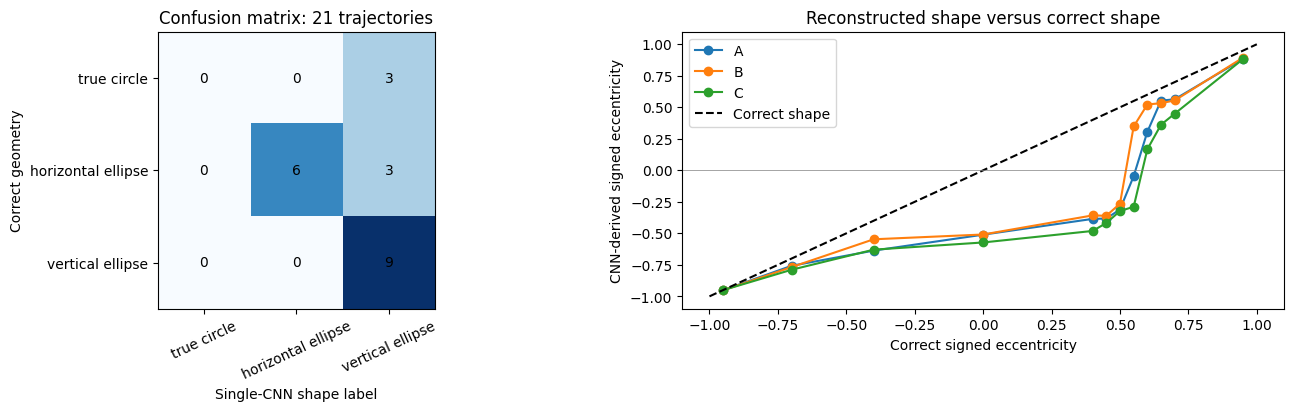

,fraction_correct
condition,
A,0.714286
B,0.714286
C,0.714286


Overall screening accuracy: 0.7142857142857143


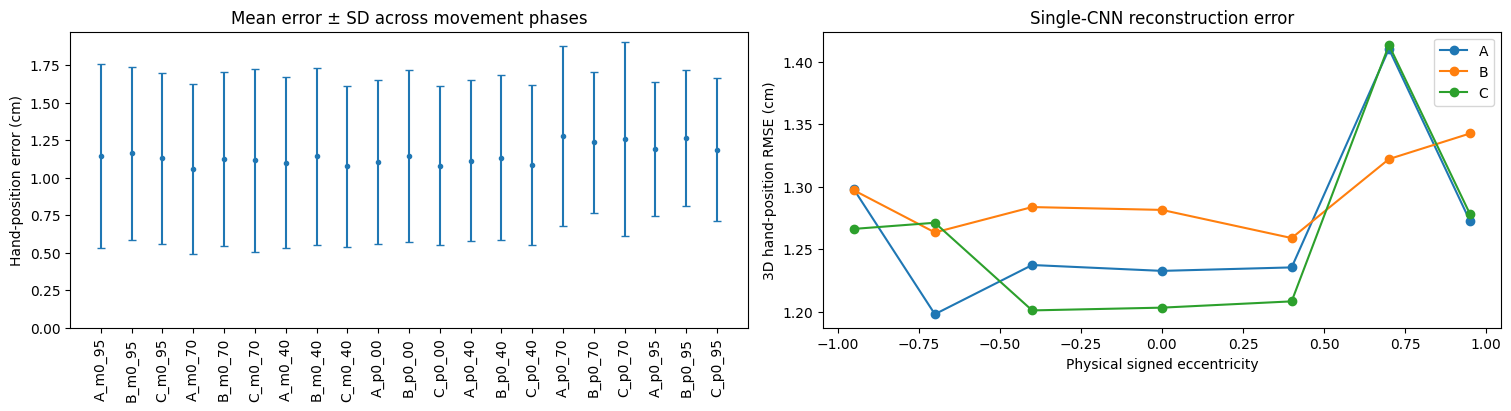

,id,mean_point_error_cm,sd_point_error_cm,rmse_3d_cm,centered_rmse_3d_cm,peak_point_error_cm
0,A_m0_95,1.145748,0.611808,1.297902,1.038416,4.630086
1,B_m0_95,1.162812,0.576643,1.297086,1.024672,4.384388
2,C_m0_95,1.131337,0.570382,1.266132,1.008366,3.907995
3,A_m0_70,1.057426,0.564721,1.197887,0.966175,3.976304
4,B_m0_70,1.122711,0.581138,1.263309,1.034754,4.232455
5,C_m0_70,1.116052,0.610328,1.271058,1.019347,4.344082
6,A_m0_40,1.098839,0.570517,1.237242,0.981516,4.125335
7,B_m0_40,1.142123,0.587803,1.283610,1.063818,3.701356
8,C_m0_40,1.074963,0.537202,1.200920,0.937546,3.573022
9,A_p0_00,1.105673,0.546490,1.232547,0.973609,3.622446


In [4]:
matrix=pd.crosstab(predictions.correct,predictions.predicted).reindex(index=CLASSES,columns=CLASSES,fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].imshow(matrix,cmap='Blues');axes[0].set(xticks=range(3),yticks=range(3),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='Single-CNN shape label',ylabel='Correct geometry',title='Confusion matrix: 21 trajectories');axes[0].tick_params(axis='x',rotation=25)
for i in range(3):
    for j in range(3):axes[0].text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
for condition,g in pse_predictions.groupby('condition'):
    g=g.sort_values('e');axes[1].plot(g.e,g.predicted_e,'o-',label=condition)
axes[1].plot([-1,1],[-1,1],'k--',label='Correct shape');axes[1].axhline(0,c='gray',lw=.5)
axes[1].set(xlabel='Correct signed eccentricity',ylabel='CNN-derived signed eccentricity',title='Reconstructed shape versus correct shape');axes[1].legend();plt.show()
accuracy=predictions.assign(is_correct=predictions.correct==predictions.predicted).groupby('condition').is_correct.mean()
display(accuracy.rename('fraction_correct').to_frame())
print('Overall screening accuracy:',(predictions.correct==predictions.predicted).mean())

errors=pd.read_csv(OUT/'trajectory_errors.csv')
fig,axes=plt.subplots(1,2,figsize=(15,4),layout='constrained')
x=np.arange(len(errors))
axes[0].errorbar(x,errors.mean_point_error_cm,yerr=errors.sd_point_error_cm,fmt='o',capsize=3,ms=3)
axes[0].set(xticks=x,xticklabels=errors.id,ylabel='Hand-position error (cm)',title='Mean error ± SD across movement phases')
axes[0].tick_params(axis='x',rotation=90);axes[0].set_ylim(bottom=0)
for condition,g in errors.groupby('condition'):
    axes[1].plot(g.e,g.rmse_3d_cm,'o-',label=condition)
axes[1].set(xlabel='Physical signed eccentricity',ylabel='3D hand-position RMSE (cm)',title='Single-CNN reconstruction error');axes[1].legend();plt.show()
display(errors[['id','mean_point_error_cm','sd_point_error_cm','rmse_3d_cm','centered_rmse_3d_cm','peak_point_error_cm']])


## 5. Single CNN versus humans, with defined uncertainty bars

The human points are the mean of the 20 participant PSEs in Table 1. **Human bars are 95% t confidence intervals of the mean**, calculated from the individual participant means in `notebooks/data/viviani_table1_participant_pses.csv`. The table's pooled inversion SD is not substituted for between-participant SD. For B−A and C−A, confidence intervals use paired differences within the same participants.

The CNN is deterministic and we have one checkpoint, so no statistical trial-to-trial confidence interval is available. **Red model bars show the interval between tested eccentricities that brackets the observed zero crossing.** They describe grid resolution, not population or prediction uncertainty. The interpolated point and bracket are both reported. Human CIs and model brackets are different quantities and should not be interpreted as equivalent error bars.

The human task was a flat/tall choice. Our model PSE is a proxy derived from equal decoded horizontal and vertical extents, not a fitted human-choice function. Human JNDs are reference values; their uncertainty cannot be recovered from the available PSE means. The stimuli remain smaller/slower, the arm posture differs, and the chest reference is approximate, so this is an exploratory comparison.

**Refined model brackets:** 15 extra trajectories use eccentricities .45, .50, .55, .60 and .65 in each velocity condition, around the initial observed crossing interval [.4, .7]. They use the identical posture, spindle coefficients and checkpoint. PSE estimates and brackets use these samples as well as the initial grid. This is numerical refinement, not training or fitting to human responses.


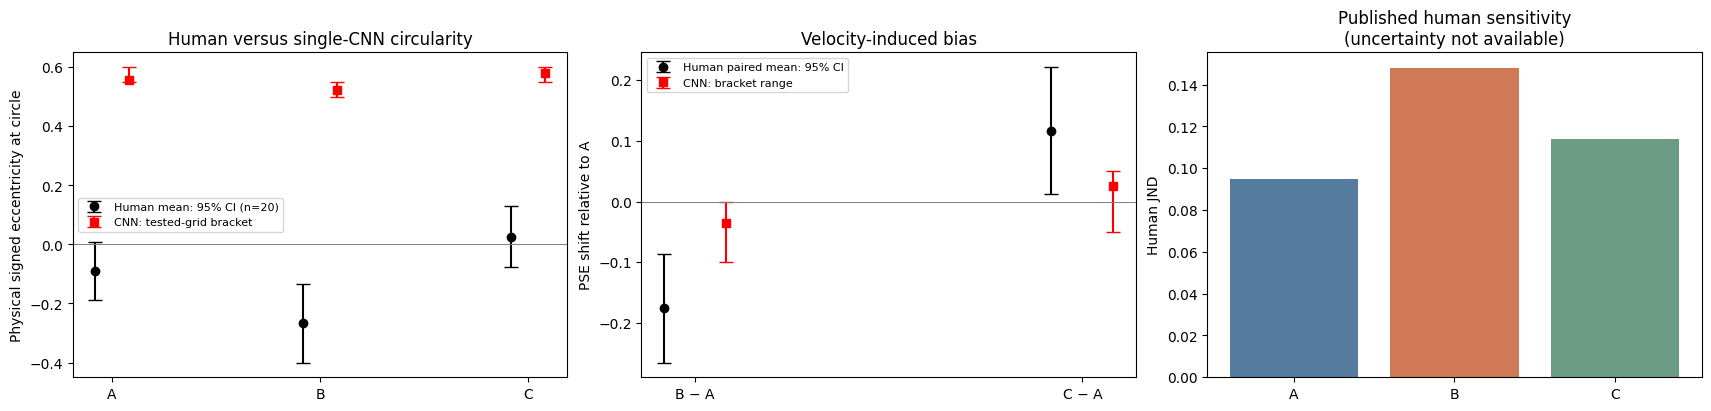

,condition,human_pse,human_sd,human_ci95_low,human_ci95_high,human_n,cnn_pse,cnn_bracket_low,cnn_bracket_high,cnn_minus_human
0,A,-0.09095,0.210926,-0.189667,0.007767,20,0.556641,0.55,0.60,0.647591
1,B,-0.26695,0.284247,-0.399982,-0.133918,20,0.521617,0.50,0.55,0.788567
2,C,0.02605,0.221113,-0.077434,0.129534,20,0.581717,0.55,0.60,0.555667


,contrast,human_mean_shift,human_ci95_low,human_ci95_high,human_n,cnn_shift,cnn_bracket_low,cnn_bracket_high
0,B-A,-0.176,-0.265442,-0.086558,20,-0.035025,-0.10,0.00
1,C-A,0.117,0.012502,0.221498,20,0.025075,-0.05,0.05


Human bars: confidence intervals over 20 participants. CNN bars: eccentricity-grid brackets, not confidence intervals.
Single-CNN reconstruction RMSE: see Section 4. Models used: 1


In [5]:
comparison=pd.read_csv(OUT/'human_model_comparison.csv')
shifts=pd.read_csv(OUT/'pse_shift_comparison.csv')
fig,axes=plt.subplots(1,3,figsize=(17,4),layout='constrained');x=np.arange(3)
human_yerr=np.vstack([comparison.human_pse-comparison.human_ci95_low,comparison.human_ci95_high-comparison.human_pse])
axes[0].errorbar(x-.08,comparison.human_pse,yerr=human_yerr,fmt='ko',capsize=5,label='Human mean: 95% CI (n=20)')
model_yerr=np.vstack([comparison.cnn_pse-comparison.cnn_bracket_low,comparison.cnn_bracket_high-comparison.cnn_pse])
axes[0].errorbar(x+.08,comparison.cnn_pse,yerr=model_yerr,fmt='rs',capsize=5,label='CNN: tested-grid bracket')
axes[0].axhline(0,c='gray',lw=.7);axes[0].set(xticks=x,xticklabels=list('ABC'),ylabel='Physical signed eccentricity at circle',title='Human versus single-CNN circularity');axes[0].legend(fontsize=8)
yerr=np.vstack([shifts.human_mean_shift-shifts.human_ci95_low,shifts.human_ci95_high-shifts.human_mean_shift])
axes[1].errorbar(np.arange(2)-.08,shifts.human_mean_shift,yerr=yerr,fmt='ko',capsize=5,label='Human paired mean: 95% CI')
yerr=np.vstack([shifts.cnn_shift-shifts.cnn_bracket_low,shifts.cnn_bracket_high-shifts.cnn_shift])
axes[1].errorbar(np.arange(2)+.08,shifts.cnn_shift,yerr=yerr,fmt='rs',capsize=5,label='CNN: bracket range')
axes[1].axhline(0,c='gray',lw=.7);axes[1].set(xticks=[0,1],xticklabels=['B − A','C − A'],ylabel='PSE shift relative to A',title='Velocity-induced bias');axes[1].legend(fontsize=8)
axes[2].bar(x,[.095,.148,.114],color=['#557b9e','#cf7957','#6b9b82']);axes[2].set(xticks=x,xticklabels=list('ABC'),ylabel='Human JND',title='Published human sensitivity\n(uncertainty not available)');plt.show()
display(comparison);display(shifts)
print('Human bars: confidence intervals over 20 participants. CNN bars: eccentricity-grid brackets, not confidence intervals.')
print('Single-CNN reconstruction RMSE: see Section 4. Models used:',provenance['n_models'])


**Reproducibility.** Outputs and checks are in `outputs/viviani_aligned/`. The active experiment is `experiments/viviani_aligned.yaml`; original and large-path diagnostic outputs are retained separately. Checkpoint and configuration hashes are recorded in `single_model_provenance.json`. To regenerate, set both run flags to `True` and run cells in order. Existing notebooks `run_pipeline.ipynb` and `mujoco_spindle_pipeline.ipynb` are not overwritten by this notebook.

**Limits.** Passing marker, fibre-length and velocity screens removes the specific failures seen previously; it does not prove that synthetic firing rates equal human afferent recordings. The scale, speed, posture, spindle approximation and fixed geometric readout all limit conclusions about the human illusion. No human perceptual responses from this study were used to train or tune the CNN for this comparison; its original movement training used synthetic inputs derived from human movement recordings.

Human CI assumptions: participant PSE means are treated as independent observations; t intervals are descriptive uncertainty in the cohort mean. The paired contrast is computed from Table 1 means rather than the paper’s Figure 3 pooled-median method. No human responses were used to select the posture, modify weights, or tune CNN predictions.

The focused 15-trajectory refinement uses `experiments/viviani_aligned_refine.yaml` and `outputs/viviani_aligned_refine/`. Both run flags regenerate that set as well. Its checkpoint checksum is checked against the main run before combining PSE data; the 21-case performance statistic remains separate.


## 6. What does the CNN predict for circles at different positions?

This adds a position experiment using the **same single CNN**. All 100 inputs are true circles of perimeter 32 cm (radius 5.09 cm), period 2.5 s, and counterclockwise direction. Each circle lies in a **vertical plane** at its grid location; right and forward specify its center, and center height is held at the reference shoulder height. Thus the image's top-down grid locates the circles; it does not turn the circles into horizontal movements.

**Grid approximation:** the original numeric grid was unavailable. `notebooks/data/circle_position_grid.csv` defines a uniform 20 × 5 approximation inferred from the image's achieved-hand arrowhead region: right −5.3 to +5.9 cm and forward 30.8 to 36.1 cm, relative to C7. The shared requested hand start is approximately (right .15, forward 33.48) cm at the same height. These are model-test coordinates, not the original numeric positions from the supplied image.

**Same starting place:** every trial begins with a .5 s hold at that one hand position, then a 1 s minimum-jerk reach to the selected circle's participant-left edge and a .5 s settling hold. The arm traces three full circles; only the **third complete cycle** is classified. A further .25 s of circular movement buffers the analyzed cycle from sequence-end filtering. The approach reach is excluded from circle-shape readout. The actual achieved common start and the physical circles are checked before the CNN runs.

**Readout:** the colored map keeps the earlier circle/horizontal/vertical extent rule (±5% around equal extents). The additional fitted major/minor axis ratio and angle detect tilted distortions that equal horizontal/vertical extents can conceal. A fitted ratio of 1 is round. Fits are descriptive summaries of the decoded path, not another neural model. The 100-panel plot shows actual and decoded vertical paths, centered separately so shape changes are distinct from position bias. The center-arrow plot separately shows errors in circle location.

**Interpretation:** decoded loops can be irregular rather than clean ellipses. The table includes ellipse-fit residuals; large residuals make a fitted ratio/angle only a rough summary. Equal horizontal/vertical extents do not establish roundness, and fitted angles are unstable for nearly round paths. The raw overlays are retained without smoothing to make these limitations visible.

**How to read the center map:** this is a view from above. Right increases to the right and forward increases upward, measured from the neck reference (C7). Each purple dot is the actual center of the circle traced by the simulated hand; its arrow tip is the CNN-predicted center. The coral ring and cross mark the shared hand starting point. A right-pointing arrow means the CNN placed the center too far right; a left-pointing arrow means it placed the center too far left. Each circle itself lies in the vertical X–Z plane, at a fixed forward distance. The body inset is a sketch. The separate vertical shape panels are centered individually to compare shapes.


Positions: 100 | CNN checkpoints: 1
Shared achieved-start difference: 0.0 cm


,n_positions
predicted,
circle,40
horizontal ellipse,22
vertical ellipse,38


Circle labels use the earlier extent rule. Rotation-aware fit ratios range from 1.013 to 1.421
Mean ellipse-fit residual (cm): 1.1099155014007254
Extent-circle cases with fitted axis ratio > 1.05: 39


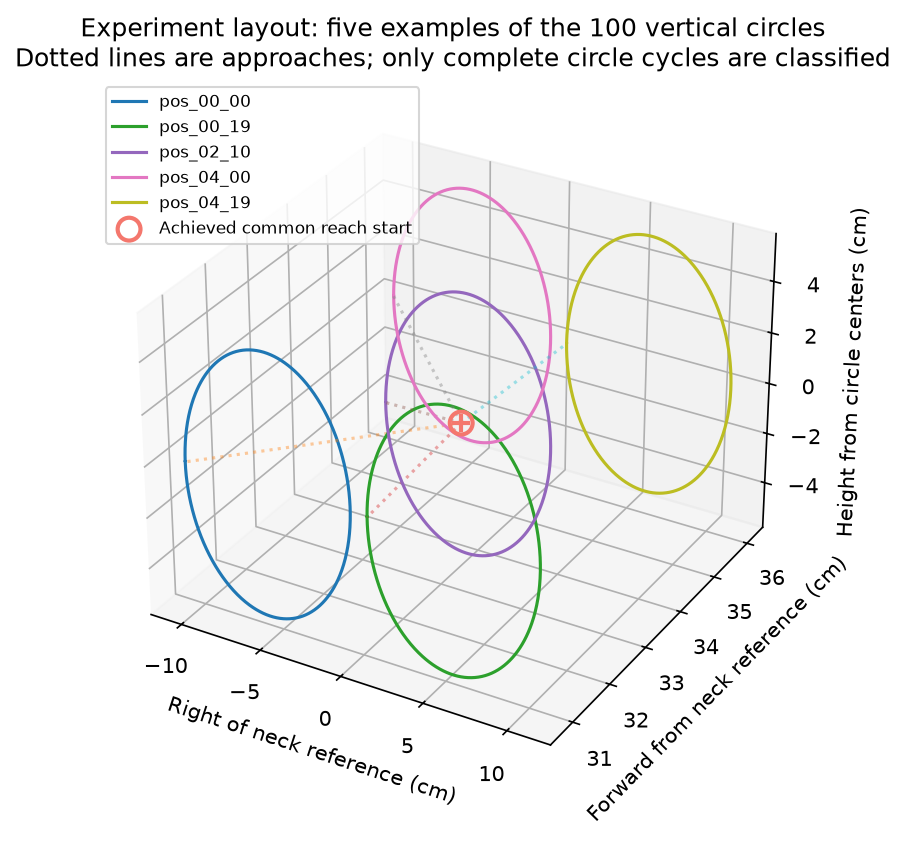

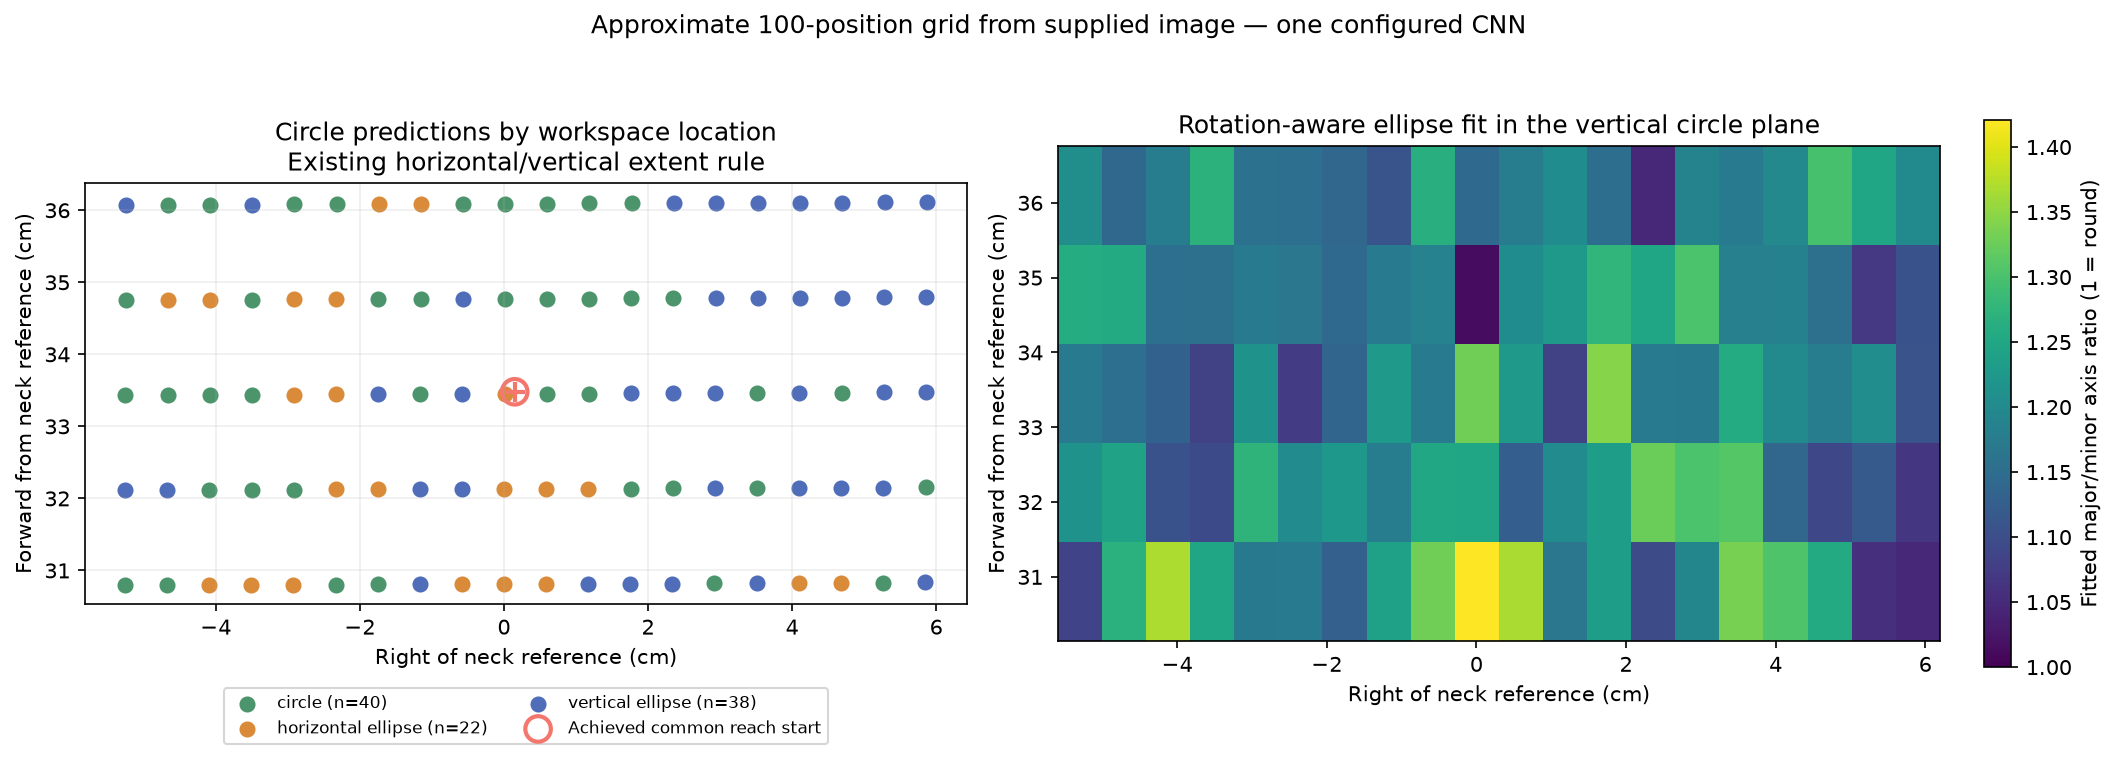

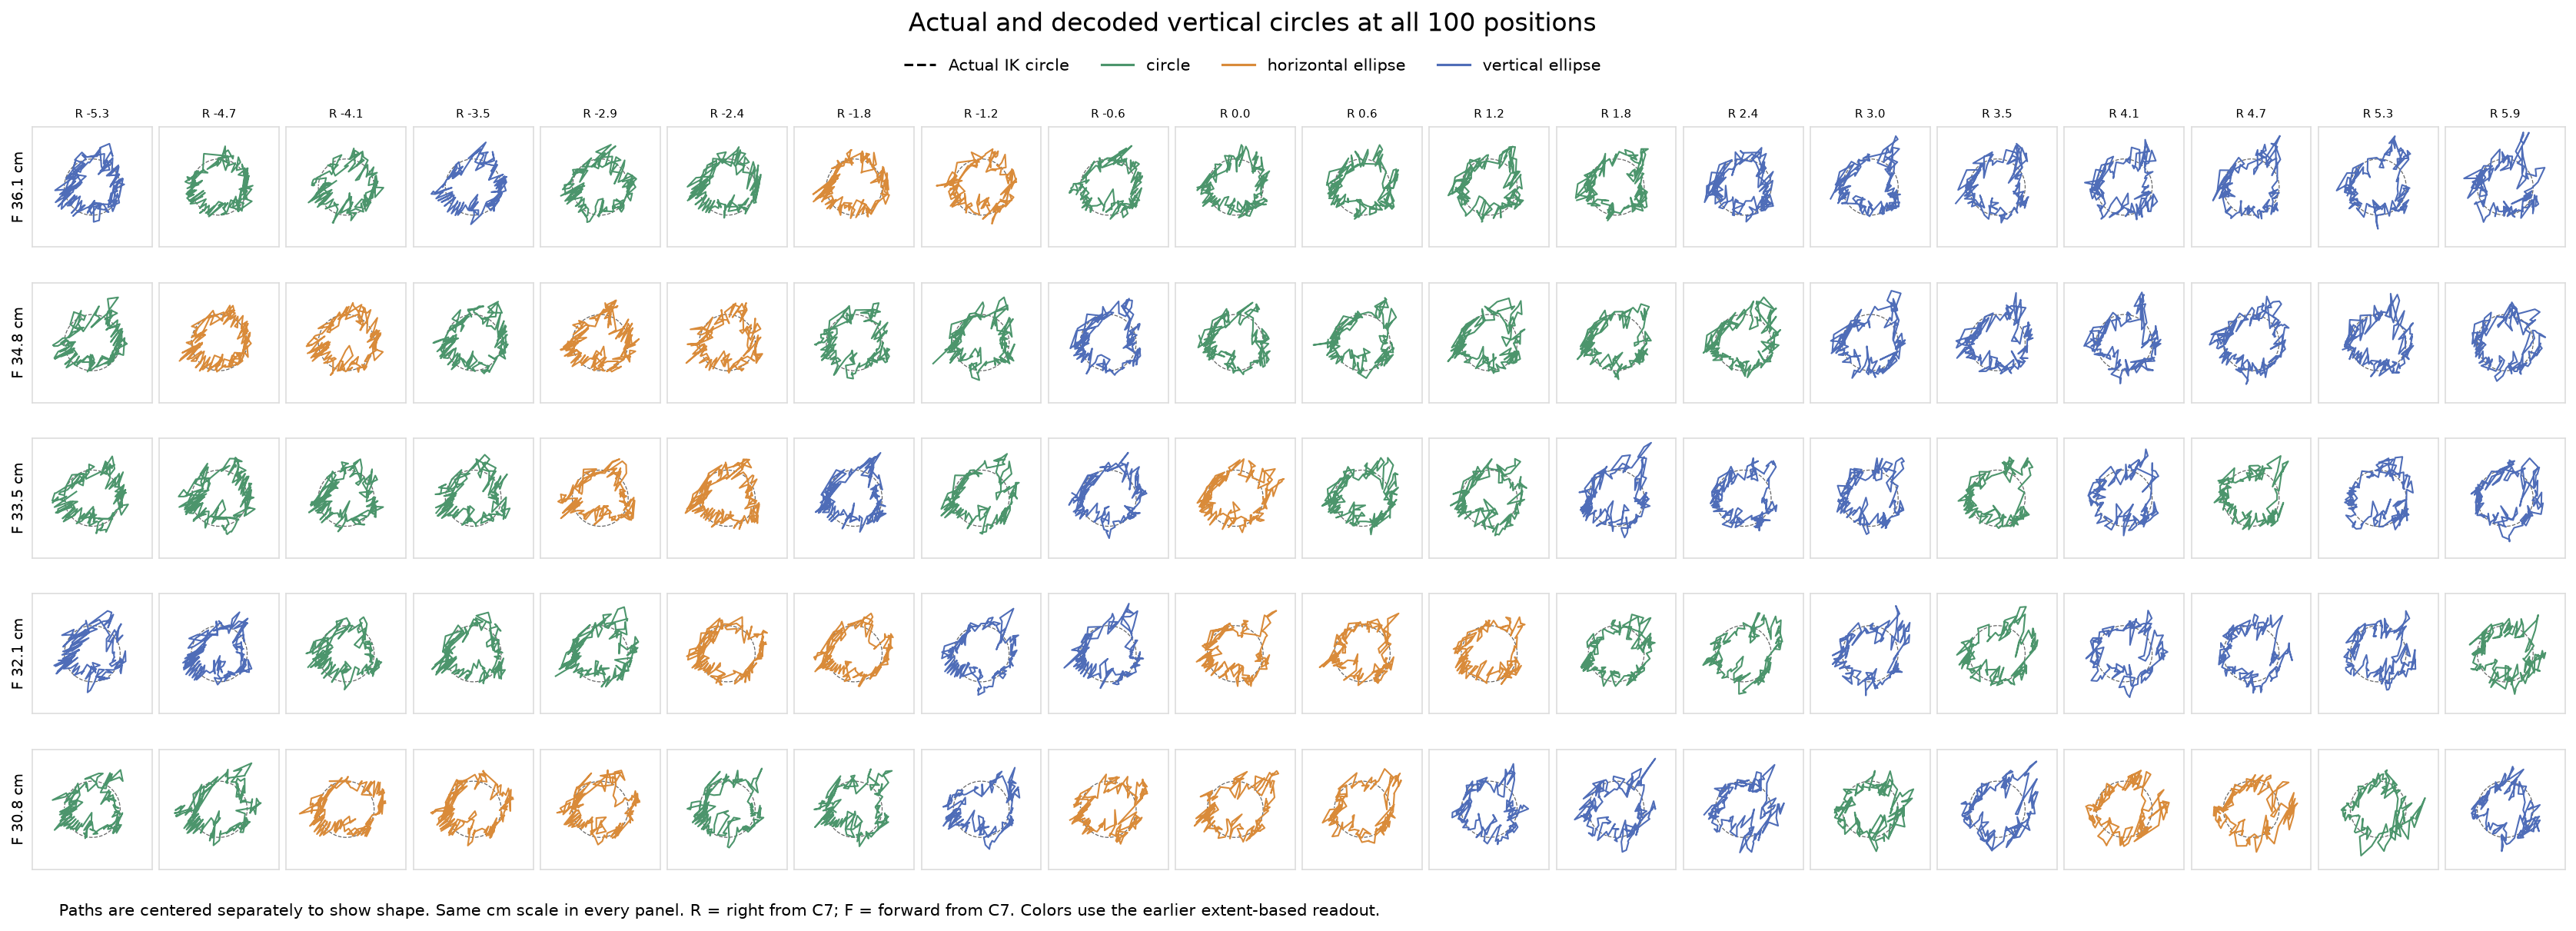

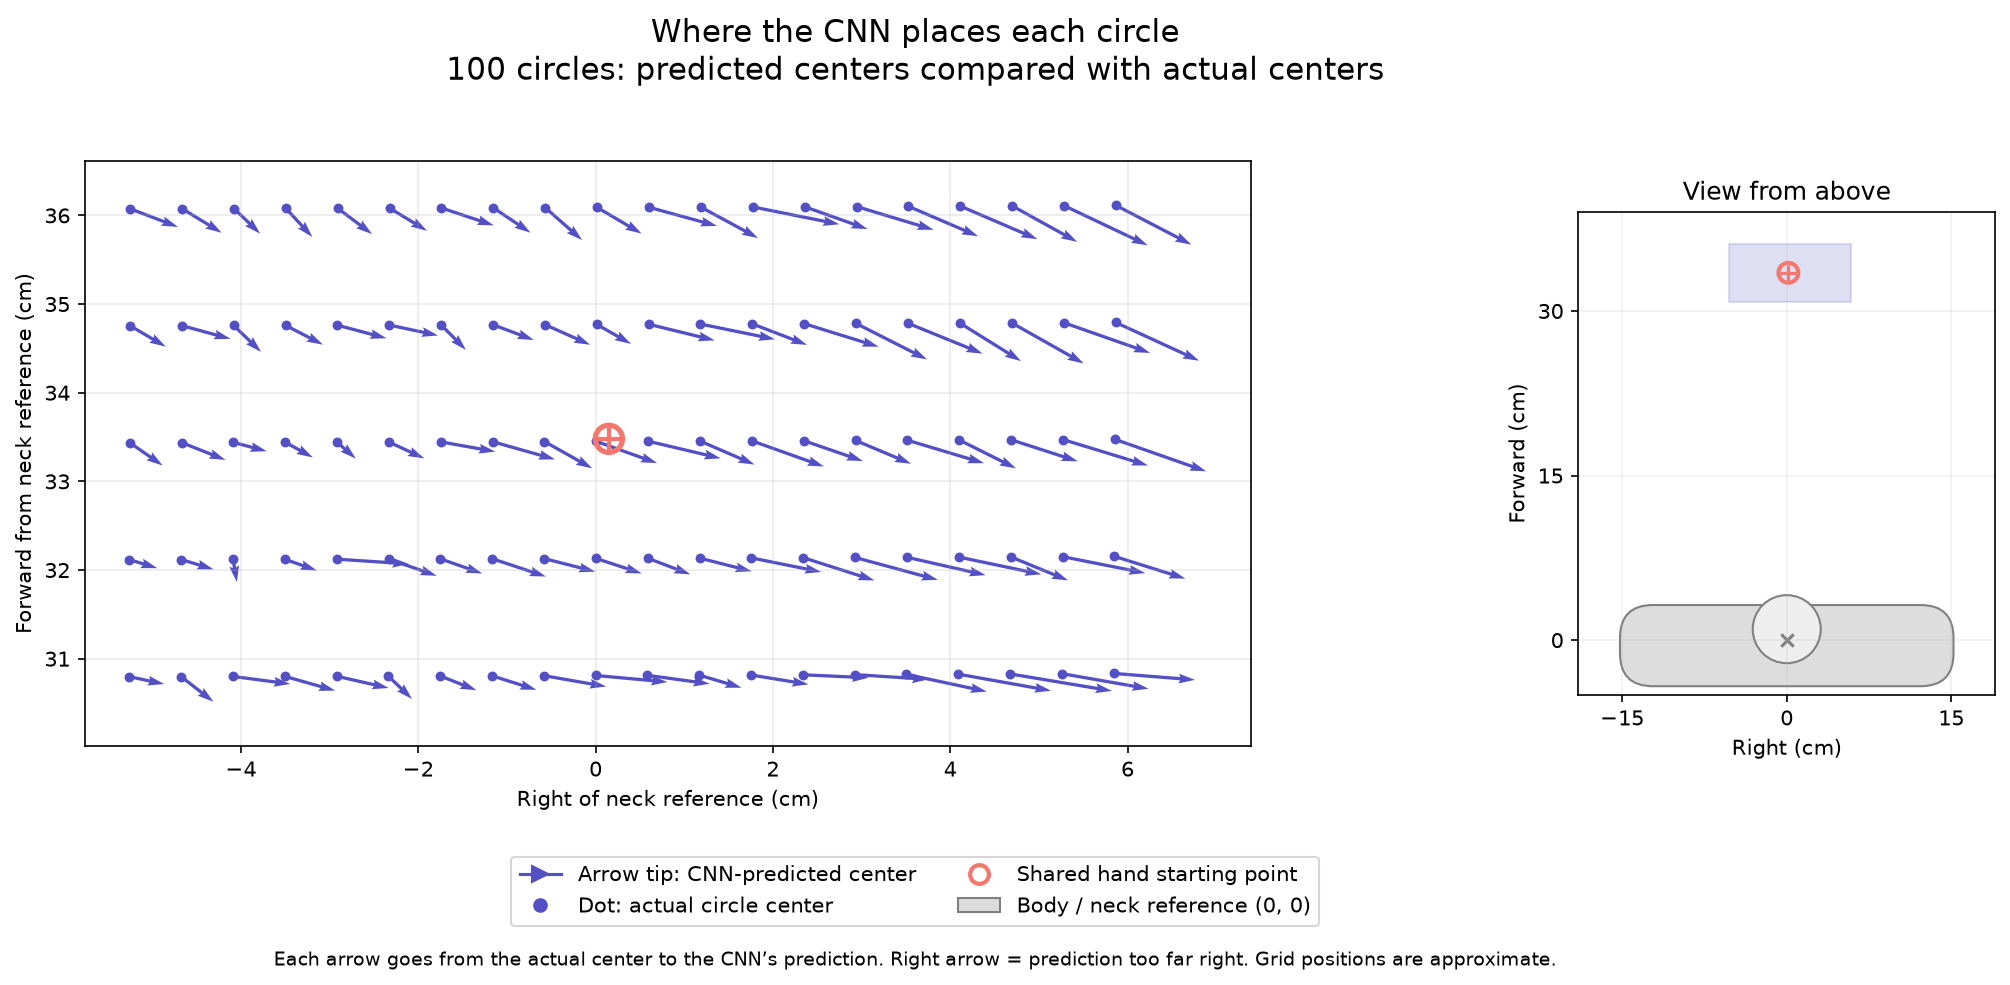

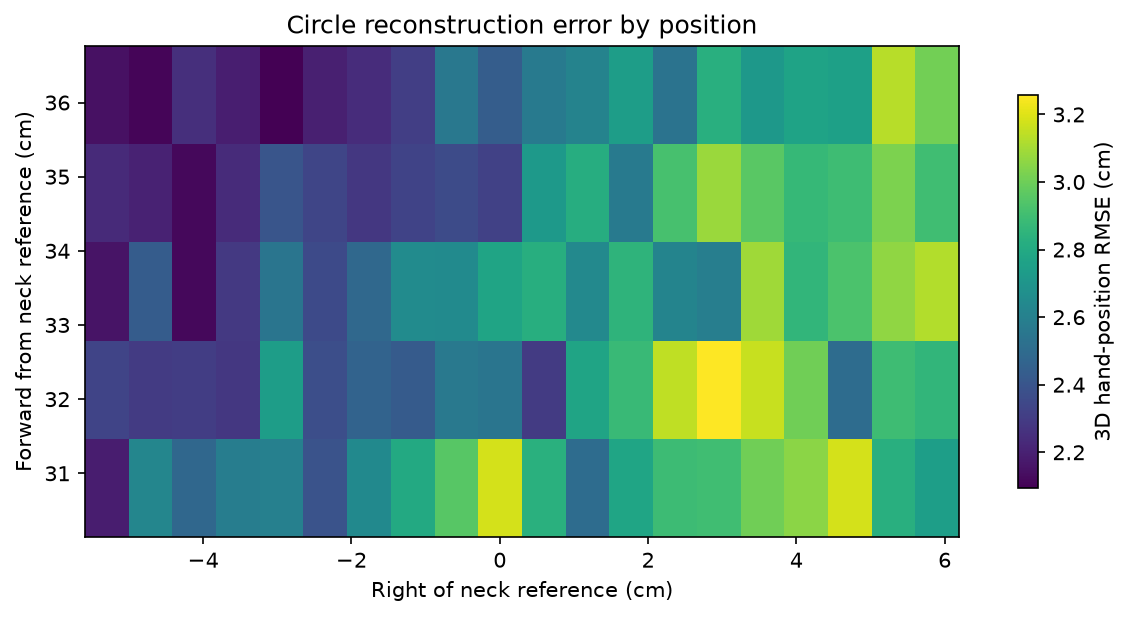

,id,right_cm,forward_cm,predicted,actual_extent_ratio,extent_ratio,actual_fitted_axis_ratio,fitted_axis_ratio,fitted_angle_deg,ellipse_fit_rmse_cm,rmse_3d_cm,centroid_error_cm,joint_out_of_bounds_fraction
0,pos_00_00,-5.300000,30.8,circle,0.993585,1.028732,1.006705,1.084625,51.011442,1.160425,2.185234,1.062700,0.0
1,pos_00_01,-4.710526,30.8,circle,0.993587,1.049788,1.006783,1.268273,22.612779,1.287805,2.626024,1.145600,0.0
2,pos_00_02,-4.121053,30.8,horizontal ellipse,0.993112,1.441040,1.006917,1.368764,11.720632,0.982767,2.481476,1.329971,0.0
3,pos_00_03,-3.531579,30.8,horizontal ellipse,0.993249,1.098684,1.006922,1.247545,24.496562,1.100293,2.585699,1.440423,0.0
4,pos_00_04,-2.942105,30.8,horizontal ellipse,0.992853,1.108440,1.007027,1.169369,21.044343,1.122899,2.601456,1.477065,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,pos_04_15,3.542105,36.1,vertical ellipse,0.994630,0.918993,1.005764,1.175722,59.661244,1.118103,2.714602,1.941473,0.0
96,pos_04_16,4.131579,36.1,vertical ellipse,0.994638,0.907866,1.005790,1.197842,56.693992,1.137785,2.769050,1.998915,0.0
97,pos_04_17,4.721053,36.1,vertical ellipse,0.994233,0.814072,1.005809,1.298539,52.722420,1.068164,2.755659,1.907930,0.0
98,pos_04_18,5.310526,36.1,vertical ellipse,0.994593,0.795256,1.005814,1.248337,54.307550,1.148203,3.130333,2.288504,0.0


Detailed CSV: /Users/macbookair2026/Documents/motor-metamers/MotorMetamersuPNC/outputs/circle_position_grid/circle_position_predictions.csv


In [6]:
# Run this section independently, or after Sections 1–5.
from pathlib import Path
import json,hashlib,subprocess,os
import numpy as np
import pandas as pd
import yaml
from IPython.display import display,Image
GRID_ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_pipeline.py').exists())
GRID_CONFIG_PATH=GRID_ROOT/'experiments/circle_positions.yaml'
GRID_CONFIG=yaml.safe_load(GRID_CONFIG_PATH.read_text())
GRID_OUT=GRID_ROOT/'outputs'/GRID_CONFIG['experiment']
RUN_POSITION_GRID=False  # True recalculates workspace trials and calls the single configured CNN.
if RUN_POSITION_GRID:
    with (GRID_ROOT/'outputs/circle_position_batch.log').open('w') as log:
        subprocess.run([str(GRID_ROOT/'.venv-opensim/bin/python'),'process/run_circle_position_batch.py','--config',str(GRID_CONFIG_PATH),'--workers','3'],cwd=GRID_ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
grid_provenance=json.loads((GRID_OUT/'single_model_provenance.json').read_text())
grid_signature=hashlib.sha256(json.dumps(GRID_CONFIG,sort_keys=True).encode()).hexdigest()
assert grid_provenance['grid_csv_sha256']==hashlib.sha256((GRID_ROOT/GRID_CONFIG['path']['circle_positions']['grid_csv']).read_bytes()).hexdigest()
assert grid_provenance['n_models']==1 and grid_provenance['config_signature']==grid_signature
assert grid_provenance['checkpoint_sha256']==hashlib.sha256((GRID_ROOT/GRID_CONFIG['proprioception']['model_path']/'model.ckpt').read_bytes()).hexdigest()
original_config=yaml.safe_load((GRID_ROOT/'experiments/viviani_aligned.yaml').read_text())
assert GRID_CONFIG['proprioception']==original_config['proprioception'], 'The grid must use the same checkpoint and spindle coefficients.'
grid_quality=pd.read_csv(GRID_OUT/'circle_position_quality.csv')
grid_results=pd.read_csv(GRID_OUT/'circle_position_predictions.csv')
grid_start=json.loads((GRID_OUT/'common_start_check.json').read_text())
assert len(grid_results)==100 and grid_quality.passed.all()
assert grid_start['max_achieved_start_difference_cm']<.05
with (GRID_OUT/'plots.log').open('w') as log:
    subprocess.run([str(GRID_ROOT/'.venv-mujoco/bin/python'),'process/plot_circle_positions.py','--output',str(GRID_OUT)],cwd=GRID_ROOT,env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(GRID_OUT/'.matplotlib')),stdout=log,stderr=subprocess.STDOUT,check=True)
grid_summary=json.loads((GRID_OUT/'circle_position_summary.json').read_text())
print('Positions:',grid_summary['n_positions'],'| CNN checkpoints:',grid_summary['n_models'])
print('Shared achieved-start difference:',grid_start['max_achieved_start_difference_cm'],'cm')
display(grid_results.groupby('predicted').size().rename('n_positions').to_frame())
print('Circle labels use the earlier extent rule. Rotation-aware fit ratios range from',round(grid_summary['fitted_axis_ratio_min'],3),'to',round(grid_summary['fitted_axis_ratio_max'],3))
print('Mean ellipse-fit residual (cm):',grid_results.ellipse_fit_rmse_cm.mean())
print('Extent-circle cases with fitted axis ratio > 1.05:',grid_summary['extent_circle_with_fitted_axis_ratio_over_1_05'])
for name in ['circle_position_layout.png','circle_position_shape_map.png','circle_position_mosaic.png','circle_position_centroid_bias.png','circle_position_error_map.png']:
    display(Image(filename=str(GRID_OUT/'figures'/name)))
display(grid_results[['id','right_cm','forward_cm','predicted','actual_extent_ratio','extent_ratio','actual_fitted_axis_ratio','fitted_axis_ratio','fitted_angle_deg','ellipse_fit_rmse_cm','rmse_3d_cm','centroid_error_cm','joint_out_of_bounds_fraction']])
print('Detailed CSV:',GRID_OUT/'circle_position_predictions.csv')


## 7. Research-meeting audit: paper, posture, spindle validity, and averaging

This audit distinguishes **what the paper reports**, **what our saved simulation actually does**, and **what remains unvalidated**. The original Sections 1–6 still show the single `0_9` checkpoint; the checkpoint comparison below is separate. No weights, original trajectories, OpenSim geometry, or original predictions were edited for this audit.

### 7.1 What the human experiment actually tested

The source is **Viviani, Baud-Bovy & Redolfi (1997)** (not Vivaldi), *Perceiving and Tracking Kinesthetic Stimuli: Further Evidence of Motor-Perceptual Interactions*. Our comparison concerns **Experiment 1**. Experiment 2 asked participants to reproduce the right-arm movement with the left arm; this notebook does not simulate that bilateral task.

**Participants and sensory conditions.** Experiment 1 involved 20 right-handed adults (8 women, 12 men). They sat in an adjustable chair, were blindfolded, and heard masking noise. A six-degree-of-freedom robot passively displaced their **right hand**. Their left hand pressed buttons to answer **“flat” or “tall.”** There was no explicit “circle” response and no drawing of a perceived circle in this experiment.

**Arm and grip (printed p. 1234, Figure 1 and Method).** Participants held an anatomical grip connected by a three-degree-of-freedom ball-and-socket joint. The hand could remain **palm down throughout motion**. The authors describe almost complete arm extension, with movement mainly involving shoulder rotation. Figure 1 is a schematic, not calibrated motion-capture data. It does not supply exact shoulder angles, elbow angles, segment lengths, scapular motion, or hand-orientation time series for the participants. Exact participant-by-participant posture cannot be recovered from this paper alone.

**Path placement and size.** The robot moved in a vertical **frontoparallel plane**, roughly 45 cm from the chest, centered on the right shoulder. All paths had perimeter **160 cm** and period **2.5 s**, giving mean tangential speed **64 cm/s**. A circle therefore had diameter **50.93 cm**. At absolute eccentricity .95, full major/minor diameters were approximately **75.44 × 23.55 cm**. The paper's quoted values 25.46–37.72 and 11.77–25.46 cm correspond to semiaxis lengths; they are not circle diameters. Signed eccentricity was positive for horizontal elongation, negative for vertical elongation, zero for a circle.

**Correction to the supplied findings notes.** The notes correctly describe overestimation of the horizontal dimension in B, but then call the resulting perceived circle a “tall” ellipse; those labels conflict. Horizontal stretching means a circle tends to appear **flat/horizontal** in B. The analogous C example is reversed as well: vertical stretching tends toward **tall/vertical**. The primary paper is used to resolve these contradictions. In the notes' simple power-law form, V ∝ R^(1−β) = curvature^(β−1); writing curvature^(−β) with β=2/3 is inconsistent with the accompanying R^(1−β) expression. The notebook's implemented path generator, not those summary equations, defines the actual stimuli.

**Kinematics (printed p. 1235).** A used constant tangential speed. B slowed near the left/right extremes; C slowed near the top/bottom. The paper states a reference kinematic eccentricity of .9 and also a maximum/minimum speed ratio of 3.205. These are mathematically inconsistent: .9 implies 1/sqrt(1−.9²) = **2.294**, whereas .95 implies **3.203** (approximately the reported 3.205). The current generator explicitly uses .9. We match the reported slowing locations, but cannot claim unambiguous exact modulation-depth replication. This ambiguity should be tested as a prespecified sensitivity analysis, not resolved by choosing whichever gives better human agreement.

**Trial sequence.** The robot brought the hand to the participant-leftmost path point. Motion was counterclockwise from the participant's viewpoint, with a smooth half-cycle acceleration. Participants chose how many cycles to experience before answering. A quarter-cycle deceleration and slow transport followed the answer. The study used adaptive, interleaved ascending/descending staircases with .05 eccentricity steps, starting at ±.70, until at least 15 reversals per staircase. Blocks generally required 40–90 trials. A/B/C block order was randomized across participants. The last 10 reversals from each staircase contributed to participant PSE estimates.

**What was measured.** The PSE is the physical shape at the flat/tall boundary; JND measures discrimination sensitivity. A PSE is not a reconstructed hand path, and a JND is not trajectory RMSE. The mean participant PSEs transcribed from Table 1 are A −.09095, B −.26695, C +.02605. The qualitative finding is perceived stretching along the direction of slowing: horizontal stretching in B and vertical stretching in C. Baseline A already has a small bias. Table-1 means and paired contrasts are not identical to the paper's Figure-3 pooled-median estimator.

### 7.2 What our notebook models, and what it does not

| Feature | Human Experiment 1 | Sections 1–5 | Section 6 |
|---|---|---|---|
| Limb | Human right arm, passively driven | One fixed OpenSim right-arm anatomy | Same model anatomy |
| Path plane | Vertical, frontoparallel | Vertical pipeline X–Z plane | Vertical X–Z circle at each right/forward grid location |
| Center | Right shoulder, ~45 cm from chest | Right-shoulder reference, ground X=.45 m | Centers distributed relative to C7, at reference shoulder height |
| Chest reference | Participant's chest | Torso X=0 approximation; no chest-surface calibration | Grid referenced to C7, not a 45-cm chest plane |
| Size | 160-cm perimeter | 32-cm perimeter, one fifth | 32-cm perimeter; 10.19-cm circle diameter |
| Period / mean speed | 2.5 s / 64 cm/s | 2.5 s / 12.8 cm/s | 2.5 s / 12.8 cm/s |
| Conditions | A, B, C | A, B, C | A only |
| Start / direction | Participant-left / counterclockwise | Matches these geometric conventions | Shared hand start, then approach to each participant-left circle point; counterclockwise |
| Onset and exposure | Smooth half-cycle ramp; participant-selected duration | Three cycles beginning immediately; no paper-matched onset ramp | .5-s hold, 1-s approach, .5-s settle, three cycles, .25-s continuation buffer |
| Analysis | Adaptive flat/tall responses | Last cycle sampled at 150 phases; fixed geometric readout | Third cycle sampled at 150 phases; reach excluded from shape readout |
| Arm extension | Almost complete extension | Substantial elbow bend | More substantial, location-dependent bend |
| Hand orientation | Palm-down maintained | Neutral forearm/wrist coordinates, not verified world palm-down | Same limitation |
| Input to perceptual system | Human afference plus other sensory/central information | Synthetic firing rates from 25 muscles | Same |
| Output | Binary flat/tall decision | Seven regression outputs; predicted joints mapped through OpenSim; separate width/height classifier | Same, plus center/ellipse-fit summaries |

**Coordinates must not be conflated.** Pipeline X is negative participant-right, pipeline Z is up, and pipeline Y is negative forward. OpenSim ground uses X forward, Y up, Z participant-right. “X–Z movement plane” here means the pipeline frame, not native OpenSim ground X–Z. Section 6's body-context map is top-down: its vertical page axis is **forward distance**, not hand height. C7 is the model's base-of-neck reference, not the hand's height or the chest surface.

**Geometry versus dynamics.** IK finds arm joint angles to follow a prescribed hand path. Muscle equilibrium and a coefficient-based transfer function generate synthetic spindle rates. This is not a forward simulation of a robot pulling a relaxed human arm, and does not reproduce grip/contact forces, participant-specific activation, fusimotor control, cutaneous feedback, effort, or a perceptual decision process. The model was trained for movement reconstruction using synthetic spindle inputs derived from human movement recordings, not on these human flat/tall judgments.

**Smaller does not mean fully equivalent.** Shrinking the path fivefold while retaining the period reduces speed and acceleration magnitudes and changes joint excursions and muscle signals. Keeping the same relative slowing locations does not preserve peripheral input statistics or guarantee the same illusion.

### 7.3 Arm audit: what has actually been checked

The saved angle arrays, rather than only the configured posture prior, show:

- Main 21 ellipse trials: elbow flexion **70.49–73.99°** across all frames.
- Fifteen refinement trials: **71.81–74.00°**.
- One hundred grid-circle trials, including reaches: **86.35–117.52°**.

Zero elbow flexion is the model's extended reference. These values establish a mismatch with the paper's almost extended arm. A configured rest angle is an IK regularization target, not an assertion that the arm holds that angle at all times. The model solves shoulder and elbow motion throughout each path.

All active configurations fix `pro_sup`, `deviation`, and `flexion` at 0°. **Zero is a model coordinate setting; it is not evidence of a palm-down hand in world coordinates.** Muscle extraction drives four proximal coordinates, leaving distal coordinates at model defaults. Previous matching of the IK and extraction defaults fixed a coordinate inconsistency but did not validate the human palm-down posture.

The cached maximum hand-path errors are **1.084 mm** in the main experiment, **0.889 mm** in refinement, and **1.233 mm** over the full grid sequences. Fiber lengths are finite and within the engineering screens, without clipping/replacement. Good endpoint tracking does not validate anatomical posture, wrapping at every possible pose, or physiological spindle signals. The earlier multi-meter teres-minor wrapping failure was real; smaller paths avoided that failure but are not a literal reproduction of the study.

**What reproducing the paper's position requires next.** Build a separate experiment with: calibrated chest-to-plane distance; right-shoulder centering; near-extended elbow over the entire path; hand orientation verified from a hand-frame normal and held palm-down; consistent distal coordinates in IK, muscle extraction, and physical decoder readout. Test the full 160-cm path and all eccentricities for reachability, joint limits, wrapping continuity, fiber lengths, and hand orientation before inference. The paper does not specify enough detail to claim an exact participant posture; document anthropometry and any chosen joint-angle targets explicitly. Do not force a visually correct hand path through a failed muscle route. The audit does **not** silently replace the current validated smaller-path experiment with an unvalidated full-size run.

### 7.4 Spindle audit: numerical checks versus physiological validity

The input tensor contains **5 Ia + 5 II responses per muscle × 25 muscles = 250 synthetic signals**, sampled at 240 Hz. Length is normalized as L/Lopt − 1; velocity and acceleration are divided by optimal fiber length. Velocity is smoothed with a 31-sample, first-order Savitzky–Golay filter before the existing transfer function is applied. It combines length, signed velocity raised to a coefficient exponent, acceleration, and a constant offset. Rates are rectified at zero and clipped at channel-specific maxima.

The fresh audit checks every saved rate in all **136 trajectories**, both the full sequence and final-cycle readout. It checks finite values, negative/upper-limit violations, zero occupancy, upper-cap occupancy, quantiles, and distance from the checkpoint's channel-wise training mean/std. It uses the exact coefficient-seed-0 channel ordering. The tables below are computed from cached artifacts, not guessed physiological limits.

Full-sequence rates:

| Experiment | Ia range | II range | Mean zero occupancy Ia / II | Upper-cap occupancy |
|---|---|---|---|---|
| Main ellipses | 0–32.15 Hz | 0–6.26 Hz | 7.76% / 5.23% | 0% |
| Refinement | 0–31.73 Hz | 0–7.40 Hz | 7.69% / 5.39% | 0% |
| Grid circles + reaches | 0–90.75 Hz | 0–8.25 Hz | 18.91% / 11.15% | 0% |

No saved rate is nonfinite or exceeds its channel cap. The selected caps range from **16.17 to 180.31 Hz**, but caps differ by channel and do not constitute a universal physiological reference interval. Zero occupancy is the fraction of channel-time values equal to zero, averaged equally over trajectories; it is not the proportion of muscles permanently silent.

**Training-statistics warning:** in the analyzed grid-circle cycles, about **6.17% of Ia channel-time values are more than 3 saved training SD from their channel mean**, and the largest absolute deviation is about **35.85 SD**. In the main ellipse cycles the corresponding fraction is about **0.106%**, with a maximum of **18.18 SD**. These are descriptive normalization diagnostics, not Gaussian probabilities. They reveal potentially important channel mismatches that an Hz-range check misses. For example, a grid-trial DELT2 Ia channel reaches **90.75 Hz**, compared with saved training mean **2.23 Hz** and SD **2.46 Hz**; a main-ellipse LAT2 Ia channel reaches **28.42 Hz**, versus mean **2.04 Hz** and SD **1.45 Hz**. These examples occur during movement, not only at onset. Channel parametrization and posture therefore require inspection; this is not just evidence of upper saturation. Very small training SD can amplify standardized deviations in other channels as well. Consequently the inputs cannot currently be described as uniformly within the model's training range.

The separate robustness run also recomputed and checked all **five coefficient groups × 136 trajectories = 680 synthetic-input sets**. Every value was finite, nonnegative and within its own channel limit; no group reached upper saturation. The highest rate over these groups was **122.23 Hz**. This extends the numerical cap check to every input parametrization used in the new comparison. The detailed channel-by-channel training-deviation analysis above concerns the original `0_9` input mapping; it is not silently generalized to the other coefficient groups.

**Verdict: finite/cap checks pass; training compatibility and physiological validity remain unresolved.** In particular, the low II rates deserve attention. These checks cannot establish that the signals match human spindle recordings in this passive, palm-down, nearly extended posture. We lack matched human afferent recordings and the full training distribution. Training mean/std comparisons can flag unusual channel values, but cannot establish distributional equivalence or normality. Being within 3 SD is not a physiological acceptance criterion; the distribution is rectified, heterogeneous, and potentially non-Gaussian. Zero output may result from lower rectification; absence of upper saturation does not prove a correct baseline. Audit unrectified transfer values, coefficient units and offsets, static holds, and matching reference movements before declaring rates “in good physiological range.” Do not clip or rescale inputs merely to obtain desired CNN predictions.

### 7.5 Seeds, averaging, and which bias this can reduce

A seed controls a random selection or training process. Repeating inference with identical inputs and the same evaluation-mode checkpoint does not create independent trials. Arbitrarily changing a runtime seed does not create new learned weights or meaningful confidence bars.

There are **five spindle-coefficient groups (0–4)** and **four saved checkpoint replicate folders (0, 1, 2, 9) per group**, hence 20 archived matched variants. Coefficient groups select different spindle parameter/channel combinations. Their CNNs must receive the corresponding channel definitions. Feeding a coefficient-group-1 signal to a group-0 CNN is a channel-identity mismatch, not a clean robustness test.

**Provenance caution:** all four group-0 checkpoint configurations record `seed: 0` internally, although their weight hashes differ. Folder endings are therefore reported as **replicate IDs**, not verified independent training random seeds. Archive provenance is required to establish exactly which training randomness changed. The five coefficient choices and four checkpoints form a crossed comparison; they are not 20 independent human participants.

**New comparison policy.** Use every available matched variant with equal weight, identical saved arm trajectories, the existing `replicate` temporal padding, the same preprocessing, the same final-cycle windows and the same geometric classifier. Keep the original `0_9` result separate. Check that the repeated `0_9` predictions reproduce the cached outputs. Do not choose variants based on human agreement. Report each variant, average continuous metrics, SD/range across variants, and label frequencies. For PSE, calculate each variant's crossing first, then summarize valid crossings and count missing/ambiguous ones. Averaging trajectories before applying a nonlinear shape label answers a different question and can hide disagreement; it is not used as the default result.

This reduces dependence on a selected checkpoint and selected spindle parametrization. **It does not guarantee less systematic prediction bias**, correct the bent-arm mismatch, make synthetic rates physiologically valid, or turn model spread into a human population confidence interval. Report coefficient-group means and within-group spread so that pooling does not hide structure. Human participants remain the statistical units for human CIs. Repeated phase samples are correlated, and repeated deterministic cycles are not independent subjects.

**Temporal-history clarification.** The full reach is supplied to the CNN, but the selected architecture has four stride-1 temporal convolutions of width 7 followed by a per-time-step linear readout: a 25-frame (~104-ms) receptive field, not persistent recurrent memory. The reach is many seconds before the third circle. Under the current feed-forward model it is outside that readout's direct receptive field; preprocessing adds local filter context, not multi-second memory. The earlier conversational suggestion that the approach might directly influence third-cycle predictions through long-term CNN history was too broad. Physical posture at the circle still matters. Endpoint padding can affect the final samples of the ellipse runs, which lack the extra grid buffer; keep this limitation separate from a reach-history effect.

### 7.6 Interpretation and next experimental decisions

The original single CNN has a strong baseline vertical shape bias, and the velocity-dependent PSE shifts are much smaller than human shifts. Its grid circles show position-dependent distortion and rightward decoded center bias. These are model outputs, not observations of human experience. A wider checkpoint comparison tests robustness, not biological truth.

Priority for reducing avoidable experimental bias: (1) make the passive-arm posture and hand orientation defensible; (2) verify synthetic spindle baselines and training compatibility without tuning to the desired perceptual answer; (3) report all matched checkpoint variants rather than a favorable subset; (4) define the classifier and uncertainty measures before comparing human data; (5) test size, speed, and modulation-depth mismatches separately. Matching human results by changing all factors simultaneously would not identify the cause.

Reproduction status: **plane/start/direction partly aligned; full size/speed, almost extended arm, maintained palm-down posture, adaptive human judgments and onset protocol are not reproduced.** This audit establishes those limits; it does not claim they have been corrected.

### 7.7 Completed all-checkpoint results: what survives averaging?

All **20 matched variants × 136 trajectories = 2,720 predictions** were evaluated with unchanged saved arm motions. Checkpoint `0_9` reproduces the cached predictions within float tolerance; its grid labels and physical RMSEs match exactly. No variant produced predicted proximal joints outside the model's limits in the analyzed samples. This is another numerical screen, not proof of physiological correctness.

**Grid location bias is not robust.** The selected `0_9` variant has mean rightward center bias **+0.635 cm**. The other **19 variants each have a negative mean rightward bias**, i.e. a leftward mean bias. Across all 20, the equal-weight mean is **−2.332 cm**, with across-variant SD **1.243 cm**. This is the average of the variants' mean signed errors over the 100 locations, not proof that every location shifts left in every variant. Even the same-coefficient group 0 changes bias direction across checkpoints, so the discrepancy is not solely caused by changing spindle coefficients. Agreement of `0_9` with the supplied reaching figure cannot be generalized to the entire checkpoint set.

**Averaging does not remove reconstruction error.** Mean per-variant RMSE over the main 21 ellipse trials is **1.421 ± 0.400 cm** (across-variant SD). Over the 100 grid circles it is **4.325 ± 1.097 cm**, with per-variant grid means ranging **2.057–7.199 cm**. These are averages of individual models' error metrics, not error of a trajectory obtained by averaging predictions. The latter is a distinct ensemble decoder and is not silently substituted for the existing CNN.

**Velocity effects are not robust either.** Mean PSEs across variants with a unique tested crossing are A **+.364** (20/20), B **+.391** (19/20), C **+.358** (19/20). One B and one C crossing could not be uniquely estimated from the tested grid. Do not replace them with zero or silently ignore the missing count. Across 19 variants with each paired contrast available, mean shifts are B−A **+.030** (SD .131) and C−A **−.0003** (SD .085). These do not reproduce the human mean shifts B−A **−.176**, C−A **+.117**. The original `0_9` directional tendency is therefore checkpoint-dependent.

**What “less bias” means here.** Using all available variants makes the analysis less dependent on choosing one favorable checkpoint. It did not make the model's signed errors vanish or improve its agreement with humans. We should report that disagreement, then test posture, size/speed, and spindle compatibility in separate controlled experiments. Existing evidence does not establish a human-like perceptual illusion in this CNN family under the current simulation settings.

**New-figure guide.** Thin shape curves are individual variants; bold curves and shaded bands show equal-weight means ± SD. PSE dots show each valid variant; red summaries use SD across variants and black human bars use 95% confidence intervals. These are intentionally different uncertainty measures. The RMSE panel shows each variant's mean error. The grid-bias panel averages signed center error at each location: positive means predicted too far right. Gray zero lines indicate no signed bias, not a physiological threshold. None of the new model-spread bars are participant confidence intervals.

**Reproducibility:** run `process/audit_viviani_setup.py` for cached signal checks (Torch environment), `process/audit_arm_snapshots.py` for pose samples (OpenSim environment), and `process/plot_viviani_audit.py` for the audit figures (Torch environment), then `process/checkpoint_sensitivity.py inference` (Torch), `process/checkpoint_sensitivity.py readout` (OpenSim), and `process/summarize_checkpoint_sensitivity.py` (Torch). Saved CSVs, checkpoint hashes, preprocessing choices and figures are under `outputs/research_audit/`. All original single-checkpoint artifacts remain in their existing folders. Checkpoint comparison is restricted to the available archive; it is not a random sample of all possible trained models.


Final-cycle firing-rate audit; fractions are channel-time occupancy, not participant uncertainty:


,experiment,type,min_Hz,max_Hz,mean_zero_fraction,mean_upper_cap_fraction,mean_abs_z_over_3_fraction,max_abs_z,nonfinite,above_cap
0,circle_position_grid,II,0.0,8.24646,0.11518,0.0,0.00000,2.53040,0,0
1,circle_position_grid,Ia,0.0,90.31396,0.19516,0.0,0.06169,35.85040,0,0
2,viviani_aligned,II,0.0,6.25720,0.05232,0.0,0.00000,1.98552,0,0
3,viviani_aligned,Ia,0.0,32.14539,0.07765,0.0,0.00106,18.18324,0,0
4,viviani_aligned_refine,II,0.0,5.99523,0.05380,0.0,0.00000,1.77939,0,0
5,viviani_aligned_refine,Ia,0.0,30.70933,0.07674,0.0,0.00088,17.86347,0,0


,elbow_min_deg,elbow_max_deg,fiber_min_mm,fiber_max_mm,max_hand_error_cm
experiment,,,,,
circle_position_grid,86.346603,117.524445,20.188393,233.091873,0.123266
viviani_aligned,70.494698,73.992279,17.319443,233.854675,0.108399
viviani_aligned_refine,71.812141,73.997849,17.561384,231.759064,0.088850


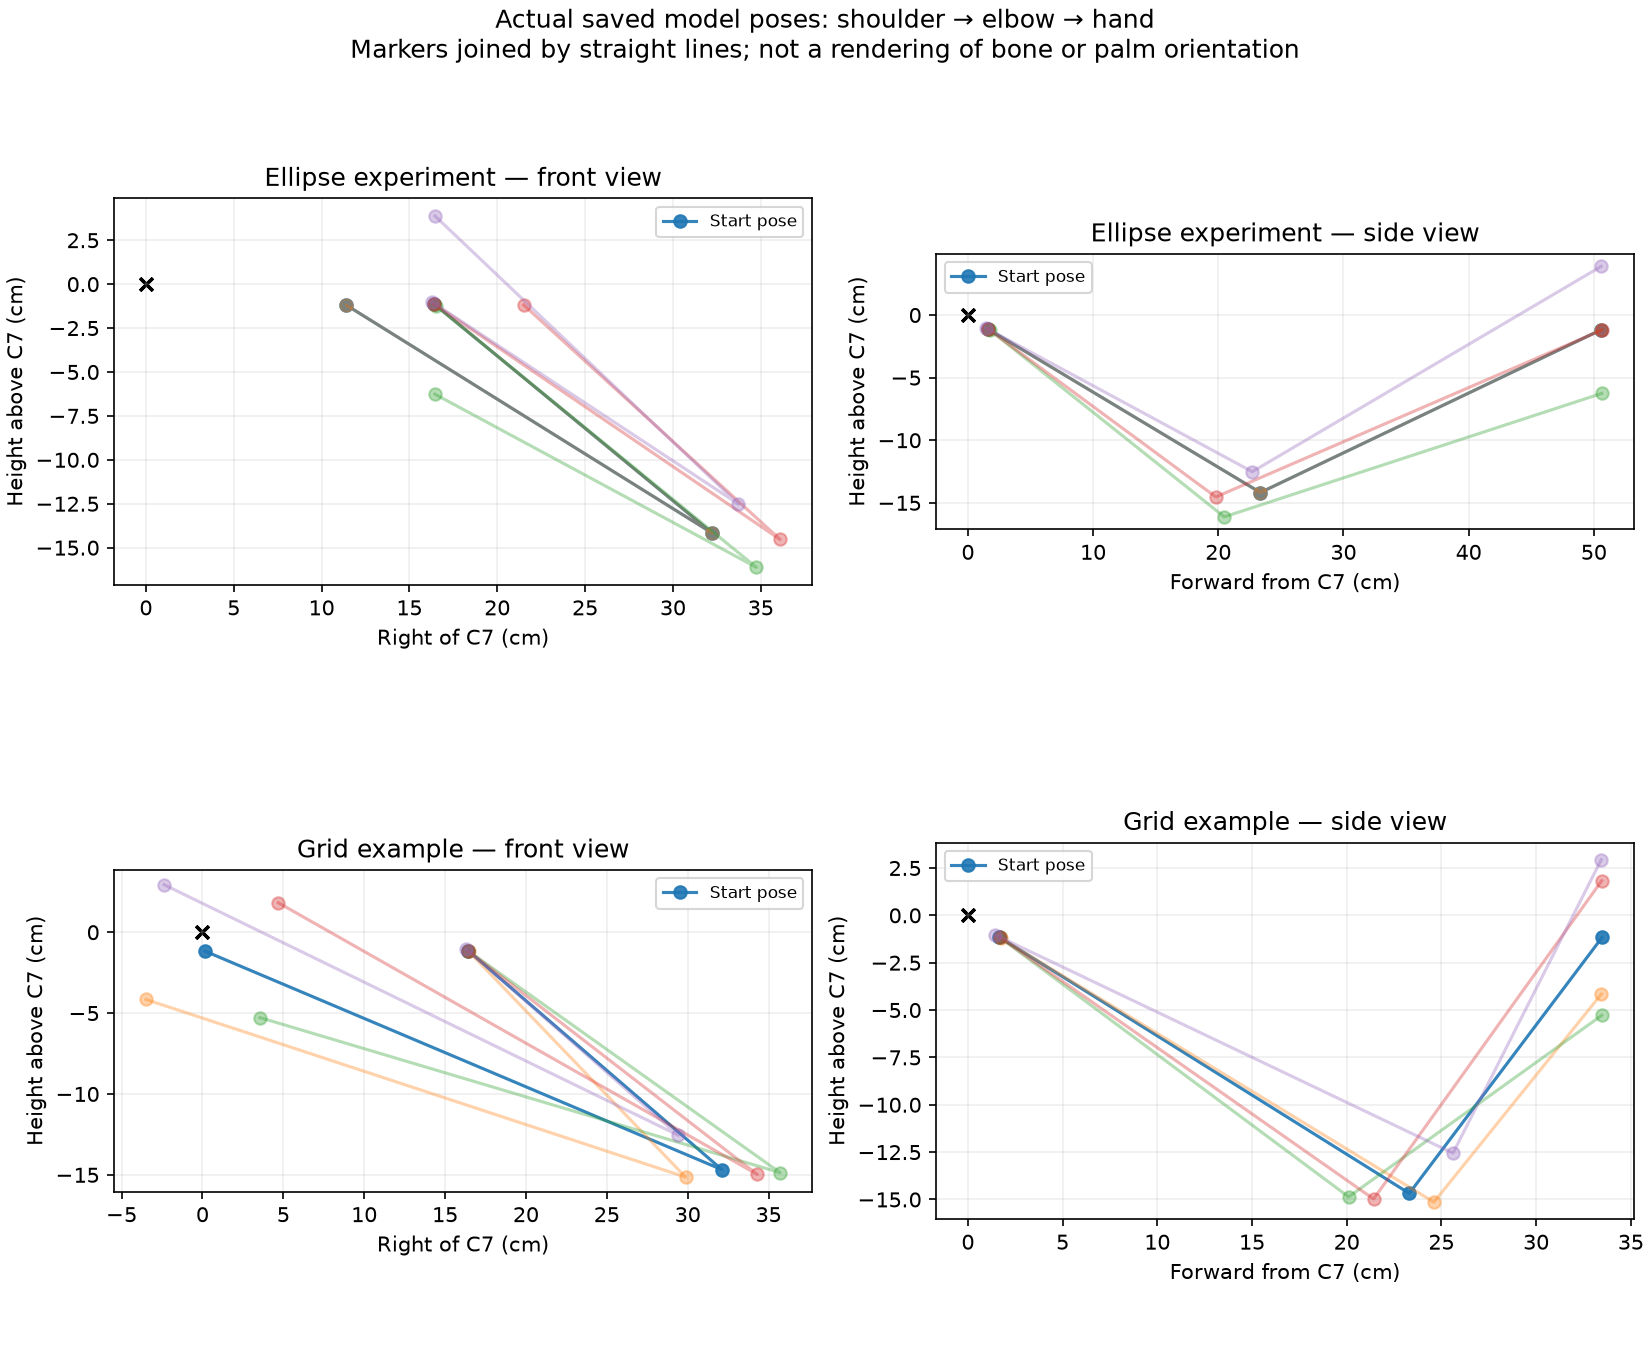

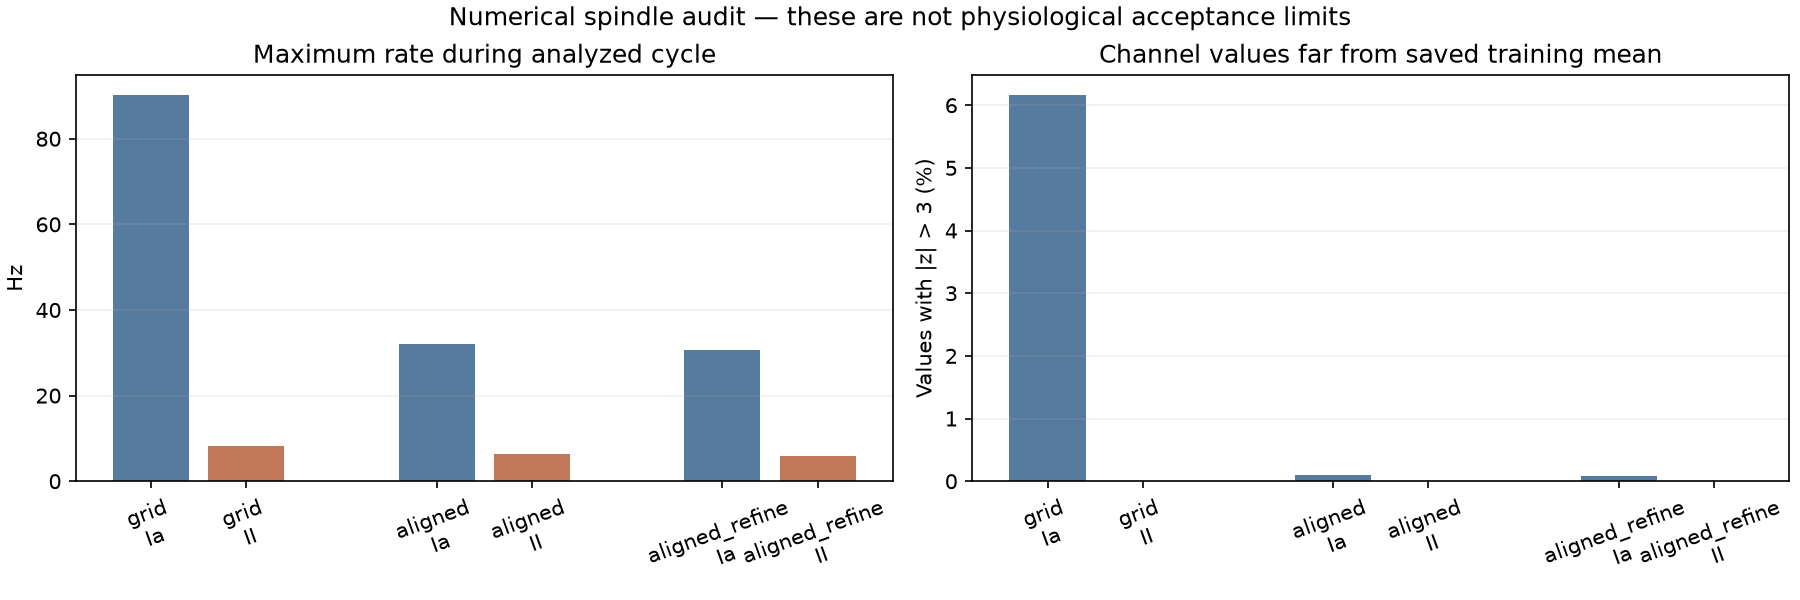

All-checkpoint comparison is separate from Sections 1–6. Spread is across archived variants, not human confidence intervals.


,experiment,n_variants,mean_rmse_cm,sd_rmse_across_variants_cm,min_variant_rmse_cm,max_variant_rmse_cm,mean_fraction_correct,sd_fraction_correct,mean_right_bias_cm,sd_right_bias_cm,mean_outside_joint_fraction
0,circle_position_grid,20,4.3247,1.0966,2.0569,7.1988,0.1525,0.1145,-2.3318,1.2435,0.0
1,viviani_aligned,20,1.4207,0.3999,0.8525,2.3425,0.7690,0.1051,-0.3040,0.5452,0.0
2,viviani_aligned_refine,20,1.4202,0.4249,0.8423,2.4312,0.6500,0.2893,-0.3013,0.5677,0.0


,condition,n_total,n_unique_crossings,mean_pse,sd_pse_across_variants,min_pse,max_pse
0,A,20,20,0.3637,0.2400,-0.1528,0.7296
1,B,20,19,0.3908,0.1605,0.1242,0.5840
2,C,20,19,0.3577,0.2732,-0.1828,0.7606


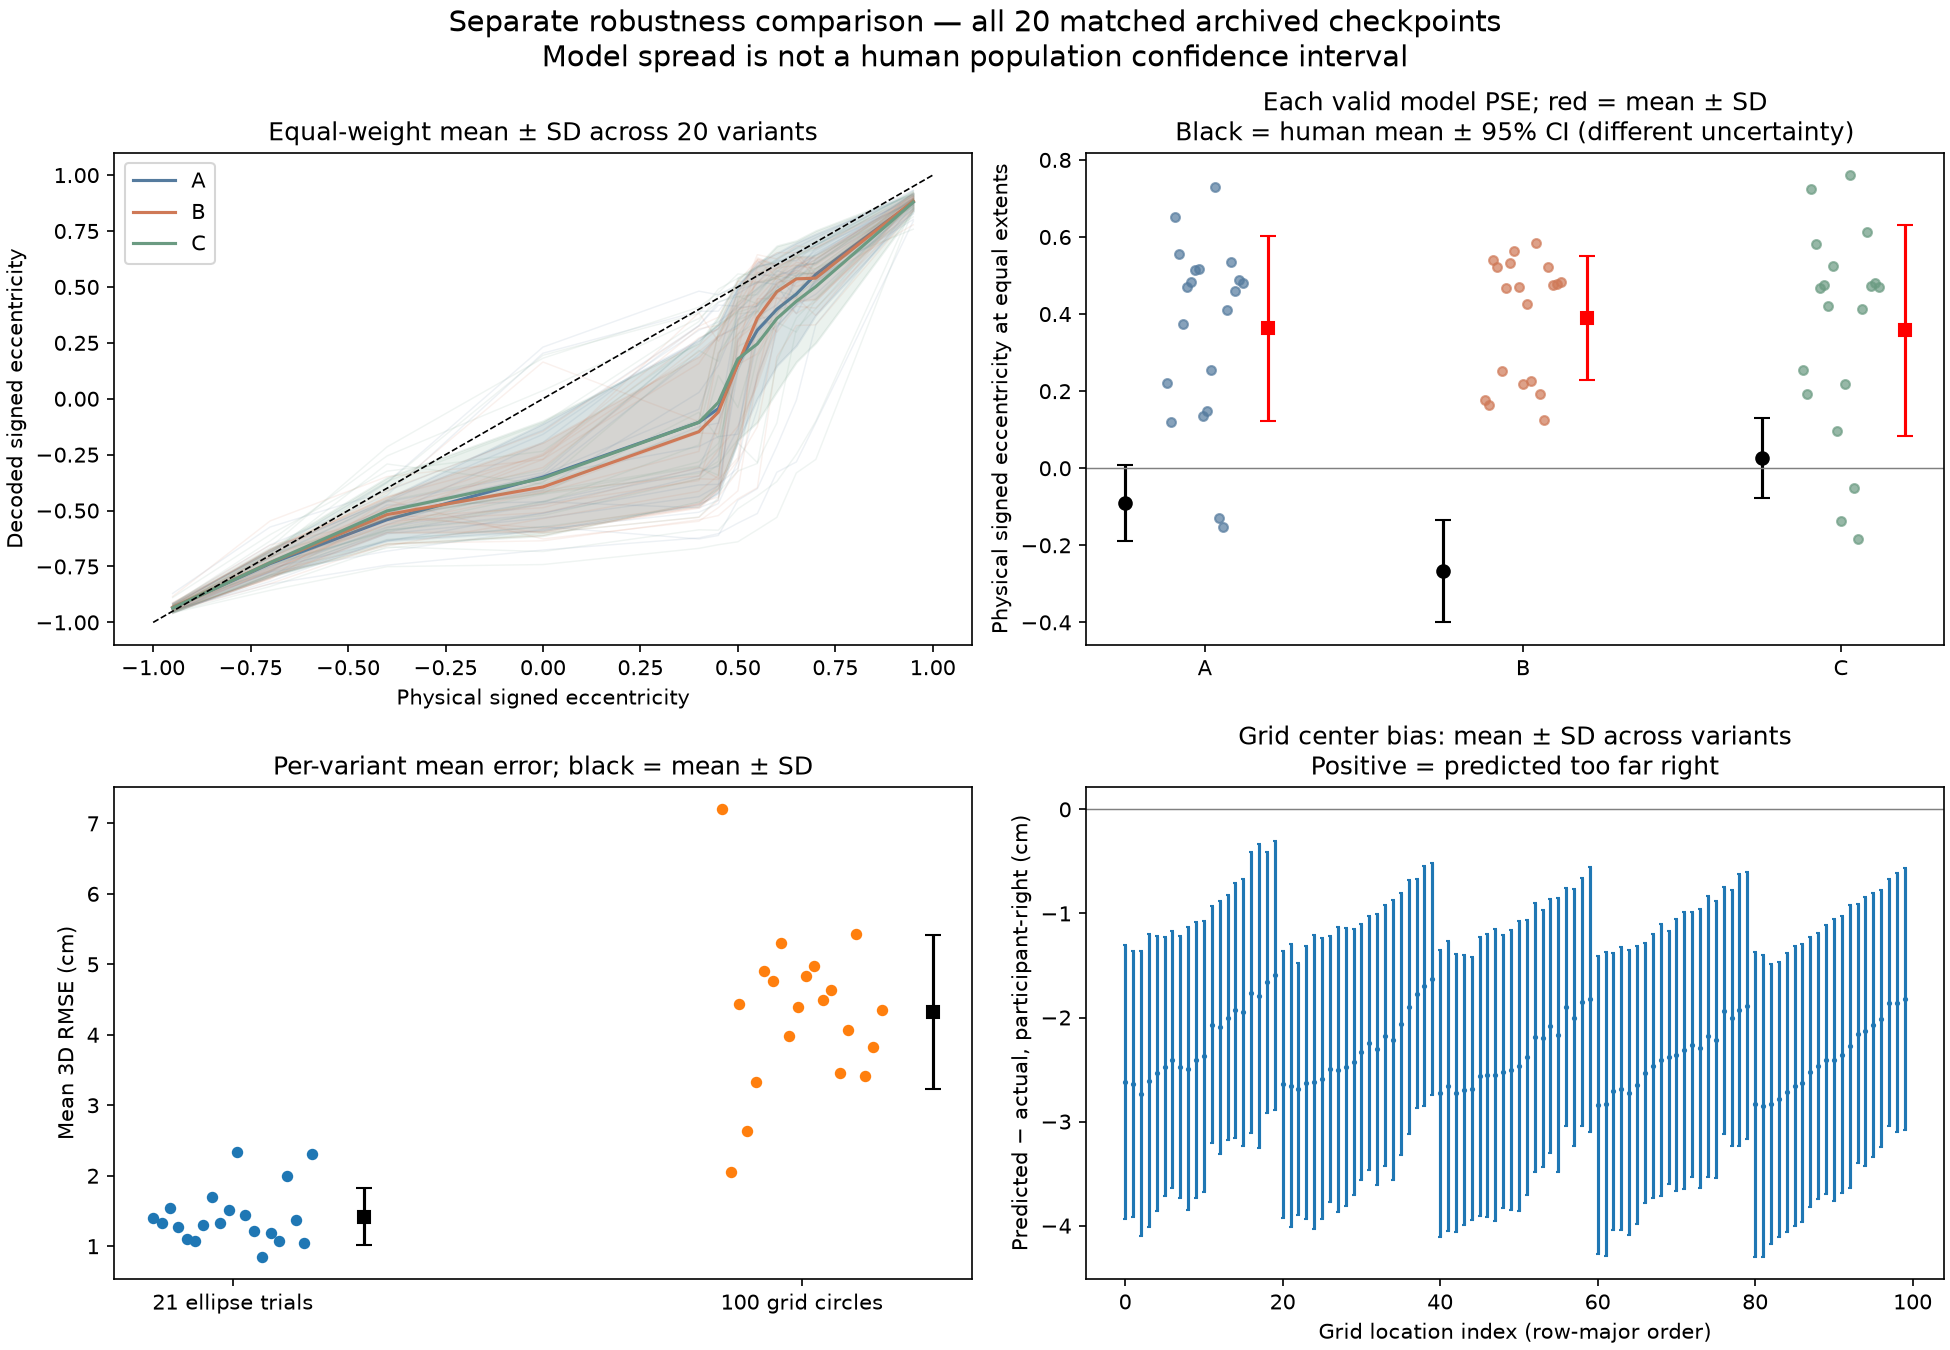

In [1]:
# Read-only audit of saved artifacts; original results and weights are preserved.
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
AUDIT_ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_pipeline.py').exists())
AUDIT_OUT=AUDIT_ROOT/'outputs/research_audit'
print('Final-cycle firing-rate audit; fractions are channel-time occupancy, not participant uncertainty:')
display(pd.read_csv(AUDIT_OUT/'spindle_summary.csv').round(5))
arm_audit=pd.read_csv(AUDIT_OUT/'arm_posture_audit.csv')
display(arm_audit.groupby('experiment').agg(elbow_min_deg=('elbow_min','min'),elbow_max_deg=('elbow_max','max'),fiber_min_mm=('fiber_min_mm','min'),fiber_max_mm=('fiber_max_mm','max'),max_hand_error_cm=('max_hand_error_cm','max')))
display(Image(filename=str(AUDIT_OUT/'arm_posture_views.png')))
display(Image(filename=str(AUDIT_OUT/'spindle_range_checks.png')))
print('All-checkpoint comparison is separate from Sections 1–6. Spread is across archived variants, not human confidence intervals.')
comparison_dir=AUDIT_OUT/'checkpoint_comparison'
display(pd.read_csv(comparison_dir/'summary_metrics.csv').round(4))
display(pd.read_csv(comparison_dir/'pse_summary.csv').round(4))
display(Image(filename=str(comparison_dir/'checkpoint_sensitivity.png')))
